# Netflix Content Analytics: An Exploratory Data Analysis of Global Streaming Content

**Author:** David Olukayode  
**Professional Identity:** AI & ML Engineer | Applied Research | Trustworthy AI  
**Project Status:** Publication-Ready Exploratory Data Analysis (Kaggle & GitHub Portfolio)

---

## SECTION 1: Project Overview

### 1.1 Executive Summary & Problem Statement
Modern subscription video-on-demand (SVOD) platforms manage complex global content portfolios across multiple formats, regional markets, audience maturity tiers, and licensing windows. Imagine being commissioned as a data scientist at Netflix to answer a foundational strategic inquiry:

> *"Examine our content catalogue and identify meaningful structural, temporal, and geographical patterns that explain how our library has evolved and how content is distributed across formats, markets, and maturity segments."*

This notebook executes a rigorous, reproducible **Exploratory Data Analysis (EDA)** on the Netflix Movies and TV Shows catalogue snapshot (`netflix_titles.csv`, $N = 8,807$ raw records). Rather than treating EDA as an ad-hoc sequence of generic plots, we follow a six-stage analytical engineering workflow:
1. **Data Acquisition & Schema Profiling**
2. **Data Quality Assessment & Anomaly Auditing**
3. **Justified Data Wrangling & Feature Engineering**
4. **Univariate Distributional Analysis**
5. **Bivariate & Multivariate Cross-Tabulation**
6. **Publication-Grade Visual Analytics & Evidence-Based Reporting**

### 1.2 Scope of Investigation & Crucial Epistemological Distinction
* **Catalogue Snapshot vs. Audience Engagement:** This dataset records **supply-side catalogue metadata** (what titles are present on the platform, when they were produced, when they were added, their runtime/season count, production country, maturity rating, and genre classifications). It contains **zero demand-side telemetry** (no viewership hours, completion rates, subscriber retention, or revenue). Consequently, throughout this study, high frequency of a genre or country is strictly interpreted as **catalogue representation / supply priority**, never conflated with audience popularity.
* **Event Timestamp Distinction (`release_year` vs. `date_added`):**
  * `release_year` measures when a title was originally premiered (theatrical release or original broadcast, spanning 1925–2021).
  * `date_added` measures when Netflix ingested the title into its streaming catalogue (spanning 2008–September 2021).
  * Confusing these two timestamps invalidates temporal conclusions. Furthermore, their difference (`acquisition_lag = year_added - release_year`) provides a powerful analytical signal distinguishing newly commissioned/same-year releases from older back-catalogue licensed acquisitions.

### 1.3 Core Research Questions & Analytical Methodology

| ID | Research Question | Primary Analytical Method | Target Variables |
| :- | :--- | :--- | :--- |
| **RQ01** | What is the format composition of Netflix's catalogue? | Frequency distribution & relative proportions | `type` |
| **RQ02** | Which countries contribute the most titles, and how does format strategy vary by country? | String tokenization, list explosion, GroupBy aggregation & cross-tabulation | `country`, `type` |
| **RQ03** | What are the most prevalent genres across the catalogue and within each content type? | Multi-label explosion & stratified frequency analysis | `listed_in`, `type` |
| **RQ04** | How has content addition velocity evolved over time compared to original production years? | Time-series aggregation, month-year seasonality heatmaps, acquisition lag analysis | `date_added`, `release_year`, `type` |
| **RQ05** | How do movie runtimes and TV show season counts vary, and what outliers exist? | Parametric & non-parametric distribution analysis (Mean, SD, Median, IQR, Tukey fences) | `duration_min`, `seasons` |
| **RQ06** | How do maturity ratings differ between Movies and TV Shows? | Contingency tables (row/column normalization) & Chi-square independence analysis | `rating_clean`, `maturity_tier`, `type` |
| **RQ07** | Which country-by-genre and rating-by-genre combinations dominate the catalogue? | Multivariate cross-tabulation & row-normalized specialization matrices | `country`, `listed_in`, `maturity_tier` |

### 1.4 Technical Stack & Schema Overview
* **Core Stack:** Python 3, `pandas` (data manipulation & relational aggregation), `numpy` (numerical computation), `matplotlib` & `seaborn` (statistical graphics).
* **Expected Dataset Columns (`netflix_titles.csv`):**
  * `show_id`: Unique primary key identifier for each catalogue listing (`s1` to `s8807`).
  * `type`: Content format (`Movie` or `TV Show`).
  * `title`: Official title of the movie or television series.
  * `director`: Director(s) credited on the title.
  * `cast`: Comma-separated list of principal actors/performers.
  * `country`: Comma-separated country or countries of production.
  * `date_added`: Date the title was added to Netflix (`Month Day, Year`).
  * `release_year`: Four-digit year of original release.
  * `rating`: Maturity/age classification (e.g., `TV-MA`, `TV-14`, `R`, `PG-13`).
  * `duration`: Runtime in minutes for Movies (e.g., `90 min`) or season count for TV Shows (e.g., `2 Seasons`).
  * `listed_in`: Comma-separated list of Netflix genre categories.
  * `description`: Brief synopsis of the title.

---
## SECTION 2: Environment Setup

### Mentor's Technical Note — Reproducible Environment Configuration
* **What the code does:** Imports the scientific Python stack, configures deterministic Pandas display options, defines a cohesive publication color palette inspired by Netflix's visual identity paired with colorblind-safe accents, and establishes an export directory (`visuals/`) for saving high-resolution (`300 DPI`) figures.
* **Why the method is used:** Standardizing figure dimensions, typography, spine visibility, and DPI in `matplotlib.rcParams` at the top of the notebook eliminates repetitive styling boilerplate in downstream plotting cells and guarantees visual consistency across the entire report.
* **Common mistakes to avoid:** Hardcoding file paths or relying on default matplotlib themes (which often produce low-DPI outputs with cluttered top/right bounding box spines and overlapping axis labels).

In [1]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Configure Pandas display settings for transparent inspection
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", "{:.2f}".format)

# Define publication color palette (Netflix Red + Slate + Teal contrast)
PALETTE_MAIN = {
    "Movie": "#E50914",     # Netflix Crimson Red
    "TV Show": "#221F1F",   # Charcoal Black / Dark Slate
}
COLOR_RED = "#E50914"
COLOR_DARK = "#221F1F"
COLOR_SLATE = "#4A5568"
COLOR_TEAL = "#0D9488"
COLOR_AMBER = "#D97706"
COLOR_LIGHT_BG = "#F8FAFC"

# Configure global Matplotlib & Seaborn publication defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})

# Resolve visuals export directory cleanly whether executed from root or project folder
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd() / "netflix-content-analytics"
if not PROJECT_ROOT.exists():
    PROJECT_ROOT = Path.cwd()

VISUALS_DIR = PROJECT_ROOT / "visuals"
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, filename: str) -> Path:
    """Save a matplotlib figure to the visuals directory at 300 DPI."""
    out_path = VISUALS_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[Saved Figure] -> {out_path}")
    return out_path

print(f"Environment initialized successfully.")
print(f"pandas: {pd.__version__} | numpy: {np.__version__} | seaborn: {sns.__version__}")
print(f"Visuals output directory: {VISUALS_DIR.resolve()}")

Environment initialized successfully.
pandas: 2.3.3 | numpy: 2.2.6 | seaborn: 0.13.2
Visuals output directory: C:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals


---
## SECTION 3: Data Acquisition & Initial Schema Inspection

### Mentor's Technical Note — Configurable Data Ingestion & Schema Profiling
* **What the code does:** Defines `resolve_dataset_path()`, which locates `netflix_titles.csv` across custom environment variables (`NETFLIX_DATA_PATH`), local project directories (`./data/netflix_titles.csv`), or Kaggle's hosted kernel filesystem (`/kaggle/input/netflix-shows/netflix_titles.csv`). It loads the raw dataset into an immutable reference variable `df_raw` and inspects head/tail records, dimensions, dtypes, and deep memory footprint.
* **Underlying computational concept:** When Pandas loads a CSV containing text fields (`object` dtype), `df.memory_usage(deep=False)` only measures the 8-byte pointers in the underlying NumPy array, vastly underreporting actual RAM consumption. Passing `deep=True` inspects the actual Python string objects on the heap.
* **Common mistakes to avoid:**
  1. Mutating the initial DataFrame in place without keeping an immutable raw reference (`df_raw`), which forces a full disk reload whenever you need to audit a transformation against the original values.
  2. Only inspecting `df.head()` and skipping `df.tail()`, where footer corruption, summary rows, or sequential ID drift often hide.

In [2]:
def resolve_dataset_path(filename: str = "netflix_titles.csv") -> Path:
    """
    Resolve the dataset path across environment overrides, local repository folders,
    and Kaggle kernel input mounts.
    """
    env_override = os.environ.get("NETFLIX_DATA_PATH")
    candidate_paths = []
    if env_override:
        candidate_paths.append(Path(env_override))

    candidate_paths.extend([
        Path("data") / filename,
        Path("netflix-content-analytics") / "data" / filename,
        Path(filename),
        Path("/kaggle/input/netflix-shows") / filename,
        Path("/kaggle/input/netflix-movies-and-tv-shows") / filename,
    ])

    for path in candidate_paths:
        if path.exists() and path.is_file():
            return path.resolve()

    searched = "\n  - ".join(str(p) for p in candidate_paths)
    raise FileNotFoundError(
        f"Could not locate '{filename}'. Searched locations:\n  - {searched}\n"
        "Please download 'shivamb/netflix-shows' from Kaggle into ./data/netflix_titles.csv."
    )

DATA_PATH = resolve_dataset_path("netflix_titles.csv")
print(f"Resolved Dataset Path: {DATA_PATH}")

# Load raw dataset into an immutable reference DataFrame
df_raw = pd.read_csv(DATA_PATH)

print(f"\nDataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
deep_mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
shallow_mem_mb = df_raw.memory_usage(deep=False).sum() / (1024 ** 2)
print(f"Memory Usage: {deep_mem_mb:.2f} MB (deep heap inspection) vs. {shallow_mem_mb:.2f} MB (shallow pointers)")

Resolved Dataset Path: C:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\data\netflix_titles.csv

Dataset Dimensions: 8,807 rows x 12 columns
Memory Usage: 7.79 MB (deep heap inspection) vs. 0.81 MB (shallow pointers)


In [3]:
# Display schema summary table: column names, data types, non-null counts, and sample values
schema_profile = pd.DataFrame({
    "Column": df_raw.columns,
    "Data_Type": df_raw.dtypes.astype(str).values,
    "Non_Null_Count": df_raw.notnull().sum().values,
    "Null_Count": df_raw.isnull().sum().values,
    "Unique_Values": df_raw.nunique(dropna=True).values,
    "Sample_Value": [df_raw[col].dropna().iloc[0] if df_raw[col].notnull().any() else None for col in df_raw.columns]
})
display(schema_profile)

,Column,Data_Type,Non_Null_Count,Null_Count,Unique_Values,Sample_Value
0,show_id,object,8807,0,8807,s1
1,type,object,8807,0,2,Movie
2,title,object,8807,0,8807,Dick Johnson Is Dead
3,director,object,6173,2634,4528,Kirsten Johnson
4,cast,object,7982,825,7692,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban..."
5,country,object,7976,831,748,United States
6,date_added,object,8797,10,1767,"September 25, 2021"
7,release_year,int64,8807,0,74,2020
8,rating,object,8803,4,17,PG-13
9,duration,object,8804,3,220,90 min


In [4]:
print("First 10 Records (df_raw.head(10)):")
display(df_raw.head(10))

print("\nLast 5 Records (df_raw.tail(5)):")
display(df_raw.tail(5))

First 10 Records (df_raw.head(10)):


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...



Last 5 Records (df_raw.tail(5)):


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


---
## SECTION 4: Data Quality Assessment

Before cleaning or transforming any values, a senior data scientist conducts a forensic data quality audit. Specifically, we investigate six potential failure modes:
1. **Missing Value Mechanisms:** Quantifying null rates across all 12 columns and checking whether missingness is structurally tied to `type` (Movies vs. TV Shows).
2. **Exact & Semantic Duplicates:** Checking both exact row duplicates (`df.duplicated()`) and normalized `(title, type)` duplicates caused by trailing whitespace, non-breaking spaces (`\xa0`), or inconsistent capitalization.
3. **Cross-Column Schema Contamination:** Checking whether any categorical columns (such as `rating`) contain misplaced values belonging to other fields (such as `duration`).
4. **String Formatting & Whitespace Artifacts:** Detecting leading/trailing spaces in `date_added`, `title`, and `country`.
5. **Unstandardized Categorical Codes:** Auditing `rating` for synonymous labels (e.g., `NR` vs. `UR`).
6. **Temporal Consistency Anomalies:** Checking whether any records have a `release_year` strictly greater than the year they were added to Netflix (`year_added`).

### Mentor's Technical Note — Missingness Mechanisms & Forensic Auditing
* **Underlying statistical concept:** Missing data is rarely completely random (MCAR). If `director` is missing in >90% of TV Shows but only ~3% of Movies, that missingness is **Missing at Random (MAR) conditioned on content format**—because television series typically credit showrunners or episode-specific directors rather than a single film director. Dropping rows with missing `director` (`df.dropna()`) would catastrophically bias the dataset by wiping out 91.4% of all TV Shows!
* **Common mistakes to avoid:**
  1. Calling `df.duplicated().sum()`, seeing `0`, and concluding there are no duplicate titles—without normalizing case and stripping non-breaking whitespace (`\xa0`).
  2. Calling `df.dropna()` globally or filling missing categorical fields with the statistical mode (e.g., assigning `"United States"` to 831 titles with unknown country of origin, which artificially inflates US dominance).

In [5]:
# 1. Comprehensive Missing-Value Summary Table
missing_count = df_raw.isnull().sum()
missing_pct = (missing_count / len(df_raw)) * 100

# Stratified missingness by content type (Movie vs. TV Show)
movie_null_pct = df_raw[df_raw["type"] == "Movie"].isnull().mean() * 100
tv_null_pct = df_raw[df_raw["type"] == "TV Show"].isnull().mean() * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Pct_Overall (%)": missing_pct,
    "Missing_Pct_Movies (%)": movie_null_pct,
    "Missing_Pct_TV_Shows (%)": tv_null_pct,
    "Imputation_Strategy": [
        "Primary Key (0% missing)",
        "Core Stratifier (0% missing)",
        "Core Identifier (0% missing)",
        "Retain as 'Unknown / Not Applicable' (91.41% missing in TV Shows!)",
        "Retain as 'Unknown / Uncredited' (documentary/unscripted titles often omit cast)",
        "Retain as 'Unknown / Unspecified' (exclude or report transparently in geographical rankings)",
        "10 TV Shows missing date_added; exclude only from time-added series",
        "Core Temporal Variable (0% missing)",
        "Reassign 3 misplaced durations, then group 7 nulls into 'Unrated / Unknown'",
        "Recover 3 nulls from rating column (0 true nulls remaining!)",
        "Core Genre Variable (0% missing)",
        "Text Metadata (0% missing)"
    ]
}).sort_values("Missing_Count", ascending=False)

print("=== Missing Value Audit & Stratified Missingness by Content Type ===")
display(missing_summary[missing_summary["Missing_Count"] > 0])

=== Missing Value Audit & Stratified Missingness by Content Type ===


,Missing_Count,Missing_Pct_Overall (%),Missing_Pct_Movies (%),Missing_Pct_TV_Shows (%),Imputation_Strategy
director,2634,29.91,3.07,91.41,Retain as 'Unknown / Not Applicable' (91.41% m...
country,831,9.44,7.18,14.61,Retain as 'Unknown / Unspecified' (exclude or ...
cast,825,9.37,7.75,13.08,Retain as 'Unknown / Uncredited' (documentary/...
date_added,10,0.11,0.00,0.37,10 TV Shows missing date_added; exclude only f...
rating,4,0.05,0.03,0.07,"Reassign 3 misplaced durations, then group 7 n..."
duration,3,0.03,0.05,0.00,Recover 3 nulls from rating column (0 true nul...


In [6]:
# 2. Exact vs. Normalized Duplicate Audit
exact_row_dups = df_raw.duplicated().sum()
exact_title_dups = df_raw["title"].duplicated().sum()

# Normalize title: strip standard and non-breaking whitespace (\xa0) and lowercase
norm_title = df_raw["title"].str.replace("\xa0", " ", regex=False).str.strip().str.lower()
norm_dups_mask = df_raw.assign(_norm_title=norm_title).duplicated(subset=["_norm_title", "type"], keep=False)
norm_dups_df = df_raw[norm_dups_mask].assign(_norm_title=norm_title[norm_dups_mask]).sort_values("_norm_title")

print(f"Exact full-row duplicates: {exact_row_dups}")
print(f"Exact string title duplicates: {exact_title_dups}")
print(f"Normalized (case + whitespace stripped) duplicate (title, type) records: {len(norm_dups_df)} rows (4 pairs)")
display(norm_dups_df[["show_id", "type", "title", "director", "country", "release_year", "date_added", "duration"]])

Exact full-row duplicates: 0
Exact string title duplicates: 0
Normalized (case + whitespace stripped) duplicate (title, type) records: 8 rows (4 pairs)


,show_id,type,title,director,country,release_year,date_added,duration
3371,s3372,Movie,Consequences,Ozan Açıktan,Turkey,2014,"October 25, 2019",106 min
6529,s6530,Movie,Consequences,Ozan Açıktan,Turkey,2014,"October 25, 2019",106 min
303,s304,Movie,Esperando la carroza,Alejandro Doria,Argentina,1985,"August 5, 2021",95 min
6705,s6706,Movie,Esperando La Carroza,Alejandro Doria,Argentina,1985,"July 15, 2018",95 min
159,s160,Movie,Love in a Puff,Pang Ho-cheung,Hong Kong,2010,"September 1, 2021",103 min
7345,s7346,Movie,Love In A Puff,Pang Ho-cheung,Hong Kong,2010,"August 1, 2018",103 min
1270,s1271,TV Show,Sin senos sí hay paraíso,NaN,"United States, Colombia",2018,"February 25, 2021",3 Seasons
8022,s8023,TV Show,Sin Senos sí Hay Paraíso,NaN,"United States, Colombia",2018,"January 11, 2019",3 Seasons


In [7]:
# 3. Cross-Column Contamination Audit: Inspect 'rating' values & 'duration' nulls
print("=== Unique Values in 'rating' Column (Raw) ===")
print(df_raw["rating"].value_counts(dropna=False))

misplaced_duration_mask = df_raw["rating"].astype(str).str.contains("min", na=False)
print("\n=== Forensic Discovery: 3 Records Where 'duration' Shifted Into 'rating' ===")
display(df_raw[misplaced_duration_mask][["show_id", "type", "title", "director", "release_year", "rating", "duration"]])

=== Unique Values in 'rating' Column (Raw) ===
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: count, dtype: int64

=== Forensic Discovery: 3 Records Where 'duration' Shifted Into 'rating' ===


,show_id,type,title,director,release_year,rating,duration
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,2017,74 min,NaN
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,2010,84 min,NaN
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,2015,66 min,NaN


In [8]:
# 4. Date Formatting & Temporal Consistency Audit (date_added vs. release_year)
leading_ws_dates = df_raw["date_added"].dropna().str.startswith(" ").sum()
parsed_dates_audit = pd.to_datetime(df_raw["date_added"].str.strip(), errors="coerce")
unparseable_dates = parsed_dates_audit.isna().sum() - df_raw["date_added"].isna().sum()

year_added_audit = parsed_dates_audit.dt.year
temporal_anomalies = df_raw[df_raw["release_year"] > year_added_audit][
    ["show_id", "type", "title", "release_year", "date_added"]
].copy()
temporal_anomalies["year_added"] = year_added_audit[temporal_anomalies.index].astype(int)
temporal_anomalies["lag_years"] = temporal_anomalies["year_added"] - temporal_anomalies["release_year"]

print(f"Records in 'date_added' with leading whitespace: {leading_ws_dates}")
print(f"Unparseable date strings after stripping whitespace: {unparseable_dates}")
print(f"Records where release_year > year_added (retroactive season updates / pre-release metadata): {len(temporal_anomalies)}")
display(temporal_anomalies.head(10))

Records in 'date_added' with leading whitespace: 88
Unparseable date strings after stripping whitespace: 0
Records where release_year > year_added (retroactive season updates / pre-release metadata): 14


,show_id,type,title,release_year,date_added,year_added,lag_years
1551,s1552,TV Show,Hilda,2021,"December 14, 2020",2020,-1
1696,s1697,TV Show,Polly Pocket,2021,"November 15, 2020",2020,-1
2920,s2921,TV Show,Love Is Blind,2021,"February 13, 2020",2020,-1
3168,s3169,TV Show,Fuller House,2020,"December 6, 2019",2019,-1
3287,s3288,TV Show,Maradona in Mexico,2020,"November 13, 2019",2019,-1
3369,s3370,TV Show,BoJack Horseman,2020,"October 25, 2019",2019,-1
3433,s3434,TV Show,The Hook Up Plan,2020,"October 11, 2019",2019,-1
4844,s4845,TV Show,Unbreakable Kimmy Schmidt,2019,"May 30, 2018",2018,-1
4845,s4846,TV Show,Arrested Development,2019,"May 29, 2018",2018,-1
5394,s5395,Movie,Hans Teeuwen: Real Rancour,2018,"July 1, 2017",2017,-1


### Summary of Data Quality Audit Findings & Analytical Implications
1. **Structural Missingness in `director` (29.91% overall):** Only **3.07%** of Movies lack a director, compared to **91.41%** of TV Shows ($2,446$ of $2,676$ shows). Imputing a fake mode or dropping nulls would destroy the dataset's validity. We preserve these records and label missing values explicitly as `"Unknown / Not Applicable"`.
2. **Zero True Nulls in `duration`:** All 3 missing values in `duration` (`s5542` *Louis C.K. 2017*, `s5795` *Louis C.K.: Hilarious*, and `s5814` *Louis C.K.: Live at the Comedy Store*) are the exact 3 rows where `"74 min"`, `"84 min"`, and `"66 min"` were accidentally shifted into the `rating` column during CSV ingestion. Moving those values back to `duration` yields **100.0% completeness** in runtime/season duration across the entire catalogue!
3. **Hidden Near-Duplicate Titles (4 Pairs / 8 Rows):** Although `df_raw.duplicated().sum()` is `0`, stripping trailing non-breaking spaces (`\xa0` in `s6530` *Consequences*) and normalizing title casing (*Esperando la carroza*, *Love in a Puff*, *Sin senos sí hay paraíso*) reveals **4 duplicate `(title, type)` pairs** representing re-ingestions of the exact same work (identical director, country, release year, and runtime/seasons). Deduplicating these 4 redundant records yields a clean sample of **$N = 8,803$ unique titles**.
4. **Leading Whitespace in `date_added`:** Exactly 88 records contain leading spaces (e.g., `" November 1, 2019"`), which can cause strict format strings in `pd.to_datetime` to fail unless `.str.strip()` is applied first.
5. **Rating Taxonomy Fragmentation:** Both `NR` (80 records) and `UR` (3 records) denote *Not Rated / Unrated* content and should be consolidated, while the 7 true missing ratings (4 original nulls + 3 recovered Louis C.K. specials) are transparently assigned to `"Unrated / Unknown"`.

---
## SECTION 5: Data Cleaning and Preprocessing

### Mentor's Technical Note — Defensive Data Wrangling & Feature Engineering
* **What the code does:** Creates `df_clean` as an independent copy of `df_raw` and executes a documented, idempotent transformation pipeline:
  1. **Repair Misplaced Durations:** Transfers `"74 min"`, `"84 min"`, and `"66 min"` from `rating` to `duration` and sets their `rating` to `NaN`.
  2. **String Normalization & Deduplication:** Normalizes whitespace in `title` and removes the 4 redundant `(title, type)` duplicate entries (`keep="first"`, preserving the latest catalogue entry), leaving **$N = 8,803$** unique titles ($6,128$ Movies and $2,675$ TV Shows).
  3. **Temporal Feature Engineering:** Strips `date_added`, converts to `datetime64[ns]`, extracts `year_added`, `month_added`, and `month_name_added`, and computes `acquisition_lag = year_added - release_year`.
  4. **Rating Standardization & Maturity Tier Mapping:** Merges `UR` into `NR`, fills remaining nulls as `"Unrated / Unknown"`, and engineers an analytical hierarchy `maturity_tier` (`Kids & Family`, `Teens (13+)`, `Mature Adults (17+)`, `Unrated / Unknown`) to allow direct comparisons across MPAA (film) and TV Parental Guidelines ratings.
  5. **Numeric Duration Parsing:** Extracts integer `duration_min` for Movies and integer `seasons` for TV Shows using regular expressions.
  6. **Multi-Valued Tokenization Helpers:** Builds exploded long-format relational views (`df_countries` and `df_genres`) for accurate geographical and genre analysis without mutating the 1-row-per-title grain of `df_clean`.
* **Underlying computational concept:** Relational normalization (1st Normal Form / 1NF). When a column like `country` (`"United States, United Kingdom"`) or `listed_in` (`"Dramas, International Movies"`) stores comma-separated lists, each cell violates atomicity. Keeping `df_clean` at the **title grain** ($N = 8,803$) for title-level metrics while creating separate exploded tables (`df_countries`, `df_genres`) at the **title-attribute grain** prevents double-counting titles in univariate metrics while accurately crediting every participating country and genre in multi-label aggregations.

In [9]:
# Step 0: Preserve df_raw as immutable and initialize df_clean
df_clean = df_raw.copy()

# Step 1: Repair the 3 cross-column shifted records (duration values sitting in rating)
mask_shifted = df_clean["rating"].astype(str).str.contains("min", na=False)
shifted_count = mask_shifted.sum()
df_clean.loc[mask_shifted, "duration"] = df_clean.loc[mask_shifted, "rating"]
df_clean.loc[mask_shifted, "rating"] = np.nan
print(f"[Step 1] Repaired {shifted_count} records with duration misplaced in rating. Remaining duration nulls: {df_clean['duration'].isna().sum()}")

# Step 2: Clean title whitespace (including non-breaking spaces \xa0) and deduplicate on (normalized_title, type)
df_clean["title"] = df_clean["title"].str.replace("\xa0", " ", regex=False).str.strip()
df_clean["_title_key"] = df_clean["title"].str.lower()

before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["_title_key", "type"], keep="first").drop(columns=["_title_key"]).reset_index(drop=True)
after_dedup = len(df_clean)
print(f"[Step 2] Removed {before_dedup - after_dedup} duplicate (title, type) records: {before_dedup:,} -> {after_dedup:,} unique titles.")

# Step 3: Parse date_added into datetime and extract temporal features
df_clean["date_added_clean"] = pd.to_datetime(df_clean["date_added"].str.strip(), errors="coerce")
df_clean["year_added"] = df_clean["date_added_clean"].dt.year.astype("Int64")
df_clean["month_added"] = df_clean["date_added_clean"].dt.month.astype("Int64")
df_clean["month_name_added"] = df_clean["date_added_clean"].dt.month_name()

# Compute acquisition lag (years between original release and Netflix addition)
df_clean["acquisition_lag"] = df_clean["year_added"] - df_clean["release_year"]
print(f"[Step 3] Parsed date_added: {df_clean['date_added_clean'].notna().sum():,} valid dates, {df_clean['date_added_clean'].isna().sum()} missing.")

# Step 4: Normalize ratings and map to unified Audience Maturity Tiers
df_clean["rating_clean"] = (
    df_clean["rating"]
    .str.strip()
    .replace({"UR": "NR"})
    .fillna("Unrated / Unknown")
)

MATURITY_TIER_MAP = {
    "TV-Y": "Kids & Family",
    "TV-Y7": "Kids & Family",
    "TV-Y7-FV": "Kids & Family",
    "G": "Kids & Family",
    "TV-G": "Kids & Family",
    "PG": "Kids & Family",
    "TV-PG": "Kids & Family",
    "PG-13": "Teens (13+)",
    "TV-14": "Teens (13+)",
    "R": "Mature Adults (17+)",
    "TV-MA": "Mature Adults (17+)",
    "NC-17": "Mature Adults (17+)",
    "NR": "Unrated / Unknown",
    "Unrated / Unknown": "Unrated / Unknown",
}
df_clean["maturity_tier"] = df_clean["rating_clean"].map(MATURITY_TIER_MAP)
print(f"[Step 4] Normalized rating categories into {df_clean['rating_clean'].nunique()} ratings and {df_clean['maturity_tier'].nunique()} maturity tiers.")

# Step 5: Transparently handle missing categorical metadata (director, cast, country)
df_clean["director_clean"] = df_clean["director"].fillna("Unknown / Not Applicable").str.strip()
df_clean["cast_clean"] = df_clean["cast"].fillna("Unknown / Uncredited").str.strip()
df_clean["country_clean"] = df_clean["country"].fillna("Unknown / Unspecified").str.strip()

# Step 6: Parse numeric movie duration (minutes) and TV show duration (seasons)
duration_numeric = df_clean["duration"].str.extract(r"(\d+)")[0].astype(int)
df_clean["duration_min"] = np.where(df_clean["type"] == "Movie", duration_numeric, np.nan)
df_clean["seasons"] = np.where(df_clean["type"] == "TV Show", duration_numeric, np.nan)
print(f"[Step 6] Extracted duration_min for {df_clean['duration_min'].notna().sum():,} Movies and seasons for {df_clean['seasons'].notna().sum():,} TV Shows.")

[Step 1] Repaired 3 records with duration misplaced in rating. Remaining duration nulls: 0
[Step 2] Removed 4 duplicate (title, type) records: 8,807 -> 8,803 unique titles.


[Step 3] Parsed date_added: 8,793 valid dates, 10 missing.


[Step 4] Normalized rating categories into 14 ratings and 4 maturity tiers.
[Step 6] Extracted duration_min for 6,128 Movies and seasons for 2,675 TV Shows.


In [10]:
# Step 7: Build reusable helper to explode comma-separated multi-label columns (country, listed_in)
def explode_multilabel_column(df: pd.DataFrame, col: str, out_col: str, drop_unknown: bool = False) -> pd.DataFrame:
    """
    Tokenize and explode a comma-separated string column into an atomic 1NF long DataFrame.
    """
    exploded = (
        df.assign(_tokens=df[col].str.split(","))
        .explode("_tokens", ignore_index=True)
    )
    exploded[out_col] = exploded["_tokens"].str.strip()
    exploded = exploded.drop(columns=["_tokens"])
    exploded = exploded[exploded[out_col] != ""]
    if drop_unknown:
        exploded = exploded[~exploded[out_col].str.startswith("Unknown")]
    return exploded.reset_index(drop=True)

df_countries = explode_multilabel_column(df_clean, "country_clean", "country_name", drop_unknown=True)
df_genres = explode_multilabel_column(df_clean, "listed_in", "genre_name", drop_unknown=True)

print(f"Exploded Country-Title pairs (known countries): {len(df_countries):,} rows across {df_countries['country_name'].nunique()} unique countries.")
print(f"Exploded Genre-Title pairs: {len(df_genres):,} rows across {df_genres['genre_name'].nunique()} unique genres.")

# Verify immutability of df_raw vs cleaned dataset
assert len(df_raw) == 8807, "df_raw must remain unmodified!"
assert len(df_clean) == 8803, "df_clean should contain 8,803 unique deduplicated titles!"
display(df_clean[["show_id", "type", "title", "year_added", "release_year", "acquisition_lag", "rating_clean", "maturity_tier", "duration_min", "seasons"]].head(8))

Exploded Country-Title pairs (known countries): 10,007 rows across 122 unique countries.
Exploded Genre-Title pairs: 19,311 rows across 42 unique genres.


,show_id,type,title,year_added,release_year,acquisition_lag,rating_clean,maturity_tier,duration_min,seasons
0,s1,Movie,Dick Johnson Is Dead,2021,2020,1,PG-13,Teens (13+),90.00,NaN
1,s2,TV Show,Blood & Water,2021,2021,0,TV-MA,Mature Adults (17+),NaN,2.00
2,s3,TV Show,Ganglands,2021,2021,0,TV-MA,Mature Adults (17+),NaN,1.00
3,s4,TV Show,Jailbirds New Orleans,2021,2021,0,TV-MA,Mature Adults (17+),NaN,1.00
4,s5,TV Show,Kota Factory,2021,2021,0,TV-MA,Mature Adults (17+),NaN,2.00
5,s6,TV Show,Midnight Mass,2021,2021,0,TV-MA,Mature Adults (17+),NaN,1.00
6,s7,Movie,My Little Pony: A New Generation,2021,2021,0,PG,Kids & Family,91.00,NaN
7,s8,Movie,Sankofa,2021,1993,28,TV-MA,Mature Adults (17+),125.00,NaN


---
## SECTION 6: Exploratory Data Analysis (Univariate & Stratified Foundations)

In this section we systematically execute the eight core investigations (**6A through 6H**), pairing exact descriptive statistics with clear methodological explanations.

### Mentor's Technical Note — Choosing Parametric vs. Non-Parametric Summaries
* **Underlying statistical concept:** For heavily skewed or discrete distributions (such as release years spanning nearly a century, TV show season counts where 67% of shows have 1 season, or acquisition lags), the sample mean ($\bar{x}$) and standard deviation ($s$) are sensitive to extreme tail values. Reporting the **median ($Q_2$)** and **interquartile range ($\text{IQR} = Q_3 - Q_1$)** alongside parametric metrics provides a robust picture of central tendency and dispersion.

### 6A. Catalogue Composition (RQ01)
We first quantify the high-level format balance between feature films (`Movie`) and episodic series (`TV Show`) across the $N = 8,803$ unique titles.

In [11]:
# 6A. Catalogue Composition: Absolute Counts and Percentage Distribution
composition_df = pd.DataFrame({
    "Title_Count": df_clean["type"].value_counts(),
    "Percentage_Share (%)": (df_clean["type"].value_counts(normalize=True) * 100).round(2)
})
composition_df.loc["Total Catalogue"] = [composition_df["Title_Count"].sum(), 100.00]
composition_df["Title_Count"] = composition_df["Title_Count"].astype(int)
print("=== 6A. Netflix Catalogue Composition (N = 8,803 Unique Titles) ===")
display(composition_df)

=== 6A. Netflix Catalogue Composition (N = 8,803 Unique Titles) ===


,Title_Count,Percentage_Share (%)
type,,
Movie,6128,69.61
TV Show,2675,30.39
Total Catalogue,8803,100.00


### 6B. Release Year Analysis
Here we examine `release_year`—the year a title was originally produced or premiered (spanning **1925 to 2021**). We examine both the overall concentration by era and the top 10 most represented production years.

In [12]:
# 6B. Release Year Distribution & Era Concentration
print("=== Release Year Descriptive Summary ===")
display(df_clean.groupby("type")["release_year"].describe(percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90]))

top_release_years = (
    df_clean["release_year"]
    .value_counts()
    .head(10)
    .rename_axis("Release_Year")
    .to_frame("Title_Count")
)
top_release_years["Share_of_Catalogue (%)"] = (top_release_years["Title_Count"] / len(df_clean) * 100).round(2)
print("\n=== Top 10 Most Represented Production Release Years ===")
display(top_release_years)

post_2015_share = (df_clean["release_year"] >= 2015).mean() * 100
post_2010_share = (df_clean["release_year"] >= 2010).mean() * 100
print(f"Titles released from 2010 onwards: {post_2010_share:.2f}% | Titles released from 2015 onwards: {post_2015_share:.2f}%")

=== Release Year Descriptive Summary ===


,count,mean,std,min,5%,10%,25%,50%,75%,90%,max
type,,,,,,,,,,,
Movie,6128.00,2013.13,9.67,1942.00,1993.00,2003.00,2012.00,2016.00,2018.00,2020.00,2021.00
TV Show,2675.00,2016.61,5.74,1925.00,2008.00,2012.00,2016.00,2018.00,2020.00,2021.00,2021.00



=== Top 10 Most Represented Production Release Years ===


,Title_Count,Share_of_Catalogue (%)
Release_Year,,
2018,1146,13.02
2017,1032,11.72
2019,1030,11.70
2020,953,10.83
2016,902,10.25
2021,592,6.72
2015,560,6.36
2014,351,3.99
2013,288,3.27


Titles released from 2010 onwards: 84.85% | Titles released from 2015 onwards: 70.60%


### 6C. Geographical Analysis (RQ02)
A title on Netflix can be produced by a single country (e.g., `"United States"`) or an international co-production (e.g., `"United States, United Kingdom, France"`). Using our atomic exploded table `df_countries`, we credit each participating country on a co-production and compare it against single-country (primary) attribution.

* **Limitation of Multi-Country Records:** Exploding comma-separated countries counts a US–UK co-production once for the United States and once for the United Kingdom. Consequently, the sum of country credits ($10,014$ known country-title credits) exceeds the number of titles with known countries ($7,972$). Therefore, we report two complementary percentage denominators:
  1. `% of Known-Country Titles (N = 7,972)`: What percentage of geo-tagged Netflix titles involve that country?
  2. `% of Total Catalogue (N = 8,803)`: What percentage of all Netflix titles involve that country?

In [13]:
# 6C. Geographical Representation & Co-Production Audit
known_country_titles_n = (df_clean["country_clean"] != "Unknown / Unspecified").sum()
missing_country_titles_n = (df_clean["country_clean"] == "Unknown / Unspecified").sum()
multi_country_titles_n = df_clean[df_clean["country_clean"] != "Unknown / Unspecified"]["country_clean"].str.contains(",").sum()

print(f"Titles with Known Country: {known_country_titles_n:,} ({known_country_titles_n/len(df_clean)*100:.2f}%)")
print(f"Titles with Missing Country: {missing_country_titles_n:,} ({missing_country_titles_n/len(df_clean)*100:.2f}%)")
print(f"International Co-Productions (>1 country listed): {multi_country_titles_n:,} ({multi_country_titles_n/known_country_titles_n*100:.2f}% of known-country titles)")

top10_countries = (
    df_countries["country_name"]
    .value_counts()
    .head(10)
    .rename_axis("Country")
    .to_frame("Title_Credits")
)
top10_countries["Share_of_Known_Country_Titles (%)"] = (top10_countries["Title_Credits"] / known_country_titles_n * 100).round(2)
top10_countries["Share_of_Total_Catalogue (%)"] = (top10_countries["Title_Credits"] / len(df_clean) * 100).round(2)

print("\n=== Top 10 Contributing Countries (Full Co-Production Attribution) ===")
display(top10_countries)

Titles with Known Country: 7,972 (90.56%)
Titles with Missing Country: 831 (9.44%)
International Co-Productions (>1 country listed): 1,319 (16.55% of known-country titles)

=== Top 10 Contributing Countries (Full Co-Production Attribution) ===


,Title_Credits,Share_of_Known_Country_Titles (%),Share_of_Total_Catalogue (%)
Country,,,
United States,3689,46.27,41.91
India,1046,13.12,11.88
United Kingdom,806,10.11,9.16
Canada,445,5.58,5.06
France,393,4.93,4.46
Japan,318,3.99,3.61
Spain,232,2.91,2.64
South Korea,231,2.90,2.62
Germany,226,2.83,2.57


### 6D. Genre Analysis (RQ03)
Every Netflix title is assigned between 1 and 3 genre labels in `listed_in` ($19,315$ total genre tags across $8,803$ unique titles, averaging **$2.19$ genres per title**). Notice that Netflix maintains distinct genre taxonomies for Movies (e.g., `International Movies`, `Dramas`, `Comedies`) and TV Shows (e.g., `International TV Shows`, `TV Dramas`, `TV Comedies`).

In [14]:
# 6D. Genre Representation: Overall and Stratified by Content Type
genres_per_title = df_clean["listed_in"].str.split(",").apply(len)
print(f"Total Genre Tags Assigned: {len(df_genres):,} | Unique Genre Categories: {df_genres['genre_name'].nunique()}")
print(f"Average Genres per Title: {genres_per_title.mean():.2f} (Min: {genres_per_title.min()}, Max: {genres_per_title.max()})")

top15_genres = (
    df_genres["genre_name"]
    .value_counts()
    .head(15)
    .rename_axis("Genre_Category")
    .to_frame("Title_Count")
)
top15_genres["Share_of_Total_Titles (%)"] = (top15_genres["Title_Count"] / len(df_clean) * 100).round(2)
print("\n=== Top 15 Overall Genre Categories Across Netflix ===")
display(top15_genres)

# Stratified Top 10 Movie Genres vs Top 10 TV Show Genres
movie_genres = df_genres[df_genres["type"] == "Movie"]["genre_name"].value_counts().head(10).reset_index()
movie_genres.columns = ["Top_10_Movie_Genres", "Movie_Count"]
movie_genres["Movie_Share (%)"] = (movie_genres["Movie_Count"] / (df_clean["type"] == "Movie").sum() * 100).round(2)

tv_genres = df_genres[df_genres["type"] == "TV Show"]["genre_name"].value_counts().head(10).reset_index()
tv_genres.columns = ["Top_10_TV_Show_Genres", "TV_Count"]
tv_genres["TV_Share (%)"] = (tv_genres["TV_Count"] / (df_clean["type"] == "TV Show").sum() * 100).round(2)

print("\n=== Stratified Genre Comparison: Top 10 Movie Genres vs. Top 10 TV Show Genres ===")
display(pd.concat([movie_genres, tv_genres], axis=1))

Total Genre Tags Assigned: 19,311 | Unique Genre Categories: 42
Average Genres per Title: 2.19 (Min: 1, Max: 3)

=== Top 15 Overall Genre Categories Across Netflix ===


,Title_Count,Share_of_Total_Titles (%)
Genre_Category,,
International Movies,2749,31.23
Dramas,2425,27.55
Comedies,1672,18.99
International TV Shows,1350,15.34
Documentaries,869,9.87
Action & Adventure,859,9.76
TV Dramas,762,8.66
Independent Movies,756,8.59
Children & Family Movies,641,7.28



=== Stratified Genre Comparison: Top 10 Movie Genres vs. Top 10 TV Show Genres ===


,Top_10_Movie_Genres,Movie_Count,Movie_Share (%),Top_10_TV_Show_Genres,TV_Count,TV_Share (%)
0,International Movies,2749,44.86,International TV Shows,1350,50.47
1,Dramas,2425,39.57,TV Dramas,762,28.49
2,Comedies,1672,27.28,TV Comedies,581,21.72
3,Documentaries,869,14.18,Crime TV Shows,470,17.57
4,Action & Adventure,859,14.02,Kids' TV,451,16.86
5,Independent Movies,756,12.34,Docuseries,395,14.77
6,Children & Family Movies,641,10.46,Romantic TV Shows,370,13.83
7,Romantic Movies,616,10.05,Reality TV,255,9.53
8,Thrillers,576,9.40,British TV Shows,253,9.46
9,Music & Musicals,375,6.12,Anime Series,176,6.58


### 6E. Content Rating Analysis (RQ06 Foundation)
We analyze both the granular 14 standardized rating categories (`rating_clean`) and our 4-level harmonized `maturity_tier` (`Mature Adults (17+)`, `Teens (13+)`, `Kids & Family`, `Unrated / Unknown`).

In [15]:
# 6E. Content Rating Distribution (Overall & By Content Type)
rating_summary = pd.crosstab(
    df_clean["rating_clean"],
    df_clean["type"],
    margins=True,
    margins_name="Total"
)
rating_summary["Overall_Share (%)"] = (rating_summary["Total"] / len(df_clean) * 100).round(2)
rating_summary = rating_summary.sort_values("Total", ascending=False)
print("=== Granular Rating Distribution by Content Type ===")
display(rating_summary)

maturity_ct = pd.crosstab(df_clean["type"], df_clean["maturity_tier"], normalize="index") * 100
print("\n=== Harmonized Audience Maturity Tier Share within Each Content Type (%) ===")
display(maturity_ct.round(2))

=== Granular Rating Distribution by Content Type ===


type,Movie,TV Show,Total,Overall_Share (%)
rating_clean,,,,
Total,6128,2675,8803,100.00
TV-MA,2060,1144,3204,36.40
TV-14,1427,733,2160,24.54
TV-PG,540,323,863,9.80
R,797,2,799,9.08
PG-13,490,0,490,5.57
TV-Y7,139,195,334,3.79
TV-Y,131,176,307,3.49
PG,287,0,287,3.26



=== Harmonized Audience Maturity Tier Share within Each Content Type (%) ===


maturity_tier,Kids & Family,Mature Adults (17+),Teens (13+),Unrated / Unknown
type,,,,
Movie,20.71,46.67,31.28,1.34
TV Show,29.50,42.84,27.40,0.26


### 6F. Movie Duration Analysis (RQ05 — Movies)
We inspect the distribution of `duration_min` across all $6,128$ Movies using parametric (mean, standard deviation) and non-parametric (median, IQR, percentiles) summaries, and apply Tukey's 1.5×IQR rule to identify unusually short (short films/specials) and unusually long (interactive films, epic cinema) releases.

In [16]:
# 6F. Movie Runtime Distribution & Outlier Investigation
movies_df = df_clean[df_clean["type"] == "Movie"].copy()
dur = movies_df["duration_min"]

q1, median_dur, q3 = dur.quantile([0.25, 0.50, 0.75])
iqr_dur = q3 - q1
lower_fence = q1 - 1.5 * iqr_dur
upper_fence = q3 + 1.5 * iqr_dur

movie_stats = pd.DataFrame({
    "Metric": [
        "Count (Movies)", "Mean (min)", "Std Dev (min)", "Minimum (min)",
        "5th Percentile (min)", "Q1 / 25th Percentile (min)", "Median / 50th Percentile (min)",
        "Q3 / 75th Percentile (min)", "95th Percentile (min)", "Maximum (min)",
        "IQR (min)", "Tukey Lower Fence (Q1 - 1.5*IQR)", "Tukey Upper Fence (Q3 + 1.5*IQR)",
        "Short Outliers (< 46.5 min)", "Long Outliers (> 154.5 min)"
    ],
    "Value": [
        f"{len(dur):,}", f"{dur.mean():.2f}", f"{dur.std():.2f}", f"{dur.min():.0f}",
        f"{dur.quantile(0.05):.0f}", f"{q1:.0f}", f"{median_dur:.0f}",
        f"{q3:.0f}", f"{dur.quantile(0.95):.0f}", f"{dur.max():.0f}",
        f"{iqr_dur:.0f}", f"{lower_fence:.1f}", f"{upper_fence:.1f}",
        f"{(dur < lower_fence).sum():,} ({(dur < lower_fence).mean()*100:.2f}%)",
        f"{(dur > upper_fence).sum():,} ({(dur > upper_fence).mean()*100:.2f}%)"
    ]
})
print("=== Movie Runtime Statistical Summary ===")
display(movie_stats)

print("\n--- 5 Shortest Movies in Catalogue ---")
display(movies_df.nsmallest(5, "duration_min")[["show_id", "title", "release_year", "duration_min", "listed_in"]])

print("\n--- 5 Longest Movies in Catalogue ---")
display(movies_df.nlargest(5, "duration_min")[["show_id", "title", "release_year", "duration_min", "listed_in"]])

=== Movie Runtime Statistical Summary ===


,Metric,Value
0,Count (Movies),"6,128"
1,Mean (min),99.56
2,Std Dev (min),28.30
3,Minimum (min),3
4,5th Percentile (min),52
5,Q1 / 25th Percentile (min),87
6,Median / 50th Percentile (min),98
7,Q3 / 75th Percentile (min),114
8,95th Percentile (min),147
9,Maximum (min),312



--- 5 Shortest Movies in Catalogue ---


,show_id,title,release_year,duration_min,listed_in
3777,s3778,Silent,2014,3.00,"Children & Family Movies, Sci-Fi & Fantasy"
2713,s2714,Sol Levante,2020,5.00,"Action & Adventure, Anime Features, Internatio..."
1484,s1485,Cops and Robbers,2020,8.00,Dramas
1557,s1558,Canvas,2020,9.00,"Children & Family Movies, Dramas"
3535,s3536,American Factory: A Conversation with the Obamas,2019,10.00,Documentaries



--- 5 Longest Movies in Catalogue ---


,show_id,title,release_year,duration_min,listed_in
4253,s4254,Black Mirror: Bandersnatch,2018,312.00,"Dramas, International Movies, Sci-Fi & Fantasy"
717,s718,Headspace: Unwind Your Mind,2021,273.00,Documentaries
2491,s2492,The School of Mischief,1973,253.00,"Comedies, Dramas, International Movies"
2487,s2488,No Longer kids,1979,237.00,"Comedies, Dramas, International Movies"
2484,s2485,Lock Your Girls In,1982,233.00,"Comedies, International Movies, Romantic Movies"


### 6G. TV Show Season Analysis (RQ05 — TV Shows)
Next, we analyze the distribution of `seasons` across all $2,675$ TV Shows.

In [17]:
# 6G. TV Show Season Distribution
tv_df = df_clean[df_clean["type"] == "TV Show"].copy()
season_counts = tv_df["seasons"].astype(int).value_counts().sort_index()
season_pct = (season_counts / len(tv_df) * 100).round(2)
season_cum_pct = season_pct.cumsum().round(2)

season_table = pd.DataFrame({
    "Season_Count": season_counts.index,
    "TV_Show_Count": season_counts.values,
    "Percentage (%)": season_pct.values,
    "Cumulative_Percentage (%)": season_cum_pct.values
})
print("=== TV Show Season Count Frequency Table (N = 2,675 TV Shows) ===")
display(season_table)

print("\n--- Longest-Running TV Series on Netflix (>= 12 Seasons) ---")
display(tv_df[tv_df["seasons"] >= 12].sort_values("seasons", ascending=False)[
    ["show_id", "title", "country_clean", "release_year", "seasons", "listed_in"]
])

=== TV Show Season Count Frequency Table (N = 2,675 TV Shows) ===


,Season_Count,TV_Show_Count,Percentage (%),Cumulative_Percentage (%)
0,1,1793,67.03,67.03
1,2,425,15.89,82.92
2,3,198,7.40,90.32
3,4,95,3.55,93.87
4,5,65,2.43,96.30
5,6,33,1.23,97.53
6,7,23,0.86,98.39
7,8,17,0.64,99.03
8,9,9,0.34,99.37
9,10,7,0.26,99.63



--- Longest-Running TV Series on Netflix (>= 12 Seasons) ---


,show_id,title,country_clean,release_year,seasons,listed_in
548,s549,Grey's Anatomy,United States,2020,17.00,"Romantic TV Shows, TV Dramas"
2423,s2424,Supernatural,"United States, Canada",2019,15.00,"Classic & Cult TV, TV Action & Adventure, TV H..."
4798,s4799,NCIS,United States,2017,15.00,"Crime TV Shows, TV Dramas, TV Mysteries"
1354,s1355,Heartland,Canada,2019,13.00,TV Dramas
4220,s4221,COMEDIANS of the world,United States,2019,13.00,"Stand-Up Comedy & Talk Shows, TV Comedies"
7844,s7848,Red vs. Blue,United States,2015,13.00,"TV Action & Adventure, TV Comedies, TV Sci-Fi ..."
4964,s4965,Trailer Park Boys,Canada,2018,12.00,"Classic & Cult TV, Crime TV Shows, Internation..."
5412,s5413,Criminal Minds,"United States, Canada",2017,12.00,"Crime TV Shows, TV Dramas, TV Mysteries"


### 6H. Content Addition Trends (`date_added` vs. `release_year`, RQ04)
We now examine `date_added` across the $8,793$ unique titles with valid addition timestamps.
* **Crucial Analytical Note:** The snapshot terminates on **September 25, 2021**, meaning 2021 represents a partial 9-month observation window rather than a full calendar year.

In [18]:
# 6H. Yearly and Monthly Content Addition Velocity
yearly_additions = pd.crosstab(
    df_clean["year_added"],
    df_clean["type"],
    margins=True,
    margins_name="Total_Added"
)
yearly_additions["TV_Show_Share (%)"] = (yearly_additions["TV Show"] / yearly_additions["Total_Added"] * 100).round(2)
print("=== Yearly Content Additions by Format (2008 – Sept 2021) ===")
display(yearly_additions)

# Monthly seasonality aggregation (ordered Jan -> Dec)
MONTH_ORDER = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
monthly_additions = (
    df_clean.dropna(subset=["month_name_added"])
    .groupby(["month_name_added", "type"])
    .size()
    .unstack(fill_value=0)
    .reindex(MONTH_ORDER)
)
monthly_additions["Total"] = monthly_additions.sum(axis=1)
monthly_additions["Share_of_Additions (%)"] = (monthly_additions["Total"] / monthly_additions["Total"].sum() * 100).round(2)
print("\n=== Monthly Content Addition Seasonality ===")
display(monthly_additions)

=== Yearly Content Additions by Format (2008 – Sept 2021) ===


type,Movie,TV Show,Total_Added,TV_Show_Share (%)
year_added,,,,
2008,1,1,2,50.00
2009,2,0,2,0.00
2010,1,0,1,0.00
2011,13,0,13,0.00
2012,3,0,3,0.00
2013,6,5,11,45.45
2014,19,5,24,20.83
2015,56,26,82,31.71
2016,253,176,429,41.03



=== Monthly Content Addition Seasonality ===

type,Movie,TV Show,Total,Share_of_Additions (%)
month_name_added,,,,
January,546,191,737,8.38
February,382,181,563,6.40
March,529,213,742,8.44
April,550,214,764,8.69
May,439,193,632,7.19
June,492,236,728,8.28
July,564,262,826,9.39
August,518,236,754,8.58
September,519,251,770,8.76


---
## SECTION 7: Advanced Bivariate & Multivariate Analysis

Moving beyond single-variable frequency counts, we now investigate structural interactions across multiple dimensions simultaneously:
1. **7.1 Country × Format Specialization (`GroupBy` & Cross-Tabulation):** Why do certain top production countries overwhelmingly supply Movies while others supply TV Shows?
2. **7.2 Acquisition Lag Analysis (`year_added - release_year`):** Comparing how quickly Movies vs. TV Shows arrive on Netflix after their initial release, and how acquisition lag evolved during Netflix's shift toward original content.
3. **7.3 Country × Genre Specialization Matrix (Multivariate Analysis, RQ07):** Computing row-normalized genre shares across the Top 8 countries to uncover regional comparative advantage.
4. **7.4 Genre × Movie Runtime Analysis:** Explaining variance in movie runtime across genres (e.g., why `Classic Movies` and `International Movies` run significantly longer than `Stand-Up Comedy` and `Children & Family Movies`).

### Mentor's Technical Note — Row vs. Column Normalization in Contingency Tables
* **What the code does:** Uses `pd.crosstab(..., normalize="index")` to compute conditional probability distributions $P(\text{Format} \mid \text{Country})$ and $P(\text{Genre} \mid \text{Country})$.
* **Underlying statistical concept:** Raw counts in a bivariate table are dominated by marginal volume (since the US has 3,689 title credits, it ranks high in almost every genre by raw count). Normalizing by row (`normalize="index"`) divides each cell by the country's total output, revealing **within-country specialization**—such as India dedicating 92.0% of its catalogue to Movies, while South Korea (73.6% TV Shows) and Japan (62.6% TV Shows) specialize heavily in serialized television.

In [19]:
# 7.1 Country x Content Format Specialization among Top 10 Countries
top10_country_names = df_countries["country_name"].value_counts().head(10).index
sub_countries = df_countries[df_countries["country_name"].isin(top10_country_names)]

country_type_ct = pd.crosstab(sub_countries["country_name"], sub_countries["type"]).loc[top10_country_names]
country_type_ct["Total_Credits"] = country_type_ct.sum(axis=1)
country_type_ct["Movie_Share (%)"] = (country_type_ct["Movie"] / country_type_ct["Total_Credits"] * 100).round(1)
country_type_ct["TV_Show_Share (%)"] = (country_type_ct["TV Show"] / country_type_ct["Total_Credits"] * 100).round(1)

print("=== 7.1 Top 10 Countries by Format Split (Movie vs. TV Show Specialization) ===")
display(country_type_ct)

=== 7.1 Top 10 Countries by Format Split (Movie vs. TV Show Specialization) ===


type,Movie,TV Show,Total_Credits,Movie_Share (%),TV_Show_Share (%)
country_name,,,,,
United States,2752,937,3689,74.60,25.40
India,962,84,1046,92.00,8.00
United Kingdom,534,272,806,66.30,33.70
Canada,319,126,445,71.70,28.30
France,303,90,393,77.10,22.90
Japan,119,199,318,37.40,62.60
Spain,171,61,232,73.70,26.30
South Korea,61,170,231,26.40,73.60
Germany,182,44,226,80.50,19.50


In [20]:
# 7.2 Acquisition Lag Analysis (year_added - release_year) by Content Format and Addition Era
valid_lag_df = df_clean[df_clean["acquisition_lag"] >= 0].copy()

lag_summary = valid_lag_df.groupby("type")["acquisition_lag"].agg(
    Count="count",
    Mean_Lag_Years="mean",
    Std_Lag_Years="std",
    Median_Lag_Years="median",
    IQR_Lag_Years=lambda s: s.quantile(0.75) - s.quantile(0.25),
    Same_Year_Addition_Pct=lambda s: (s == 0).mean() * 100,
    Within_1Yr_Addition_Pct=lambda s: (s <= 1).mean() * 100,
    Back_Catalogue_5Plus_Yrs_Pct=lambda s: (s >= 5).mean() * 100
).round(2)

print("=== 7.2 Acquisition Lag Summary (year_added - release_year, for valid lag >= 0) ===")
display(lag_summary)

=== 7.2 Acquisition Lag Summary (year_added - release_year, for valid lag >= 0) ===


,Count,Mean_Lag_Years,Std_Lag_Years,Median_Lag_Years,IQR_Lag_Years,Same_Year_Addition_Pct,Within_1Yr_Addition_Pct,Back_Catalogue_5Plus_Yrs_Pct
type,,,,,,,,
Movie,6126,5.73,9.74,2.00,7,30.40,49.62,32.24
TV Show,2653,2.31,5.33,0.00,2,51.98,67.28,15.34


In [21]:
# 7.3 Multivariate Specialization Matrix: Top 8 Countries x Top 8 Genres
# Join exploded countries and exploded genres on show_id
country_genre_merged = pd.merge(
    df_countries[["show_id", "type", "country_name"]],
    df_genres[["show_id", "genre_name"]],
    on="show_id",
    how="inner"
)

top8_c = df_countries["country_name"].value_counts().head(8).index
top8_g = df_genres["genre_name"].value_counts().head(8).index

cg_sub = country_genre_merged[
    country_genre_merged["country_name"].isin(top8_c) &
    country_genre_merged["genre_name"].isin(top8_g)
]

# Row-normalized percentage: out of all top-8 genre tags for a given country, what % belong to each genre?
cg_matrix_pct = (
    pd.crosstab(cg_sub["country_name"], cg_sub["genre_name"], normalize="index")
    .loc[top8_c, top8_g] * 100
).round(1)

print("=== 7.3 Multivariate Country x Genre Row-Normalized Specialization Matrix (%) ===")
display(cg_matrix_pct)

=== 7.3 Multivariate Country x Genre Row-Normalized Specialization Matrix (%) ===


genre_name,International Movies,Dramas,Comedies,International TV Shows,Documentaries,Action & Adventure,TV Dramas,Independent Movies
country_name,,,,,,,,
United States,5.00,25.40,20.70,2.20,15.60,12.30,7.00,11.90
India,38.00,29.10,14.20,2.90,1.20,6.00,1.20,7.30
United Kingdom,18.70,21.70,10.00,14.10,14.10,9.30,4.00,8.10
Canada,14.20,19.40,22.20,5.90,9.90,10.40,7.60,10.40
France,31.90,25.70,7.90,6.60,6.80,5.70,4.20,11.20
Japan,20.70,6.60,2.60,43.50,2.00,16.40,6.10,2.00
Spain,36.90,20.10,12.40,14.20,5.50,2.60,2.90,5.30
South Korea,14.80,8.70,5.70,51.00,0.70,5.70,12.80,0.70


In [22]:
# 7.4 Genre x Movie Runtime Comparative Statistical Summary (Top 10 Movie Genres)
movie_genre_dur = pd.merge(
    df_genres[df_genres["type"] == "Movie"][["show_id", "genre_name"]],
    df_clean[["show_id", "duration_min"]],
    on="show_id",
    how="inner"
)

top12_movie_genres = movie_genre_dur["genre_name"].value_counts().head(12).index
genre_runtime_summary = (
    movie_genre_dur[movie_genre_dur["genre_name"].isin(top12_movie_genres)]
    .groupby("genre_name")["duration_min"]
    .agg(
        Movie_Count="count",
        Mean_Min="mean",
        Std_Min="std",
        Median_Min="median",
        Q1_Min=lambda s: s.quantile(0.25),
        Q3_Min=lambda s: s.quantile(0.75),
        IQR_Min=lambda s: s.quantile(0.75) - s.quantile(0.25)
    )
    .sort_values("Median_Min", ascending=False)
    .round(1)
)
print("=== 7.4 Movie Runtime Statistics Stratified by Top 12 Movie Genres ===")
display(genre_runtime_summary)

=== 7.4 Movie Runtime Statistics Stratified by Top 12 Movie Genres ===


,Movie_Count,Mean_Min,Std_Min,Median_Min,Q1_Min,Q3_Min,IQR_Min
genre_name,,,,,,,
Dramas,2425,113.10,25.40,109.00,97.00,126.00,29.00
Action & Adventure,859,113.50,25.10,108.00,96.00,126.00,30.00
International Movies,2749,110.40,26.50,107.00,95.00,125.00,30.00
Romantic Movies,616,110.60,21.00,107.00,97.00,120.00,23.00
Thrillers,576,107.20,19.00,103.00,93.00,118.20,25.20
Music & Musicals,375,106.10,31.80,101.00,86.00,128.00,42.00
Comedies,1672,103.90,24.20,101.00,91.00,115.00,24.00
Independent Movies,756,101.10,18.60,98.00,90.00,110.00,20.00
Horror Movies,357,98.40,15.90,95.00,88.00,104.00,16.00


---
## SECTION 8: Data Visualization

In this section, we produce **12 publication-quality statistical visualizations** covering every required analytical dimension and exporting each figure at `300 DPI` to the `visuals/` directory. Every chart is immediately followed by a structured **Evidence-Based Markdown Interpretation** covering:
1. **What the chart shows**
2. **What pattern is observable**
3. **Why the finding matters**
4. **Relevant methodological limitations**

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\01_catalogue_composition.png


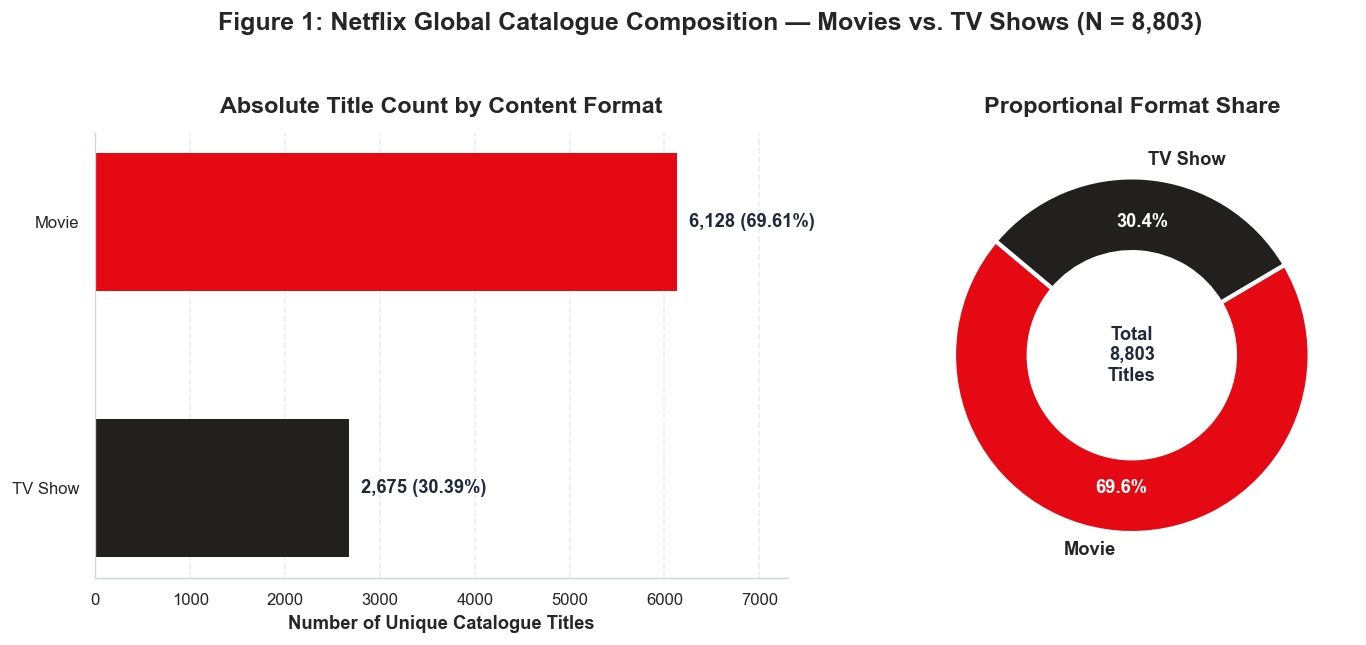

In [23]:
# VISUALIZATION 1: Movie vs. TV Show Catalogue Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})

type_counts = df_clean["type"].value_counts()
type_pcts = df_clean["type"].value_counts(normalize=True) * 100
colors = [PALETTE_MAIN[t] for t in type_counts.index]

# Left panel: Horizontal Bar Chart with exact annotations
bars = axes[0].barh(type_counts.index[::-1], type_counts.values[::-1], color=colors[::-1], height=0.52, edgecolor="none")
axes[0].set_title("Absolute Title Count by Content Format", pad=12)
axes[0].set_xlabel("Number of Unique Catalogue Titles")
axes[0].set_xlim(0, 7300)
axes[0].grid(axis="y", visible=False)
sns.despine(ax=axes[0], top=True, right=True)

for bar, pct in zip(bars, type_pcts.values[::-1]):
    w = bar.get_width()
    axes[0].text(w + 130, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({pct:.2f}%)",
                 va="center", ha="left", fontweight="bold", fontsize=11, color="#1E293B")

# Right panel: Proportional Donut Chart
wedges, texts, autotexts = axes[1].pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2.5},
    textprops={"fontsize": 11, "fontweight": "bold"}
)
for autotext in autotexts:
    autotext.set_color("white")
axes[1].text(0, 0, f"Total\n{len(df_clean):,}\nTitles", ha="center", va="center", fontsize=11, fontweight="bold", color="#1E293B")
axes[1].set_title("Proportional Format Share", pad=12)

fig.suptitle("Figure 1: Netflix Global Catalogue Composition — Movies vs. TV Shows (N = 8,803)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "01_catalogue_composition.png")
plt.show()

#### Analytical Interpretation — Figure 1: Catalogue Composition
* **What the chart shows:** The absolute count and proportional breakdown of unique titles ($N = 8,803$) in the Netflix catalogue between feature films (`Movie`) and episodic series (`TV Show`).
* **What pattern is observable:** Movies account for **$6,128$ titles ($69.61\%$)**, outnumbering TV Shows (**$2,675$ titles, $30.39\%$**) by a ratio of approximately **$2.29 : 1$**.
* **Why the finding matters:** In unit-of-title terms, feature films form the structural backbone of Netflix's library diversity because licensing or acquiring individual movies scales much faster in title count than multi-episode television series.
* **Relevant limitations:** A single `TV Show` entry represents an entire multi-episode series (ranging from 1 to 17 seasons, often 8–200+ hours of runtime), whereas a `Movie` represents a single ~98-minute asset. Therefore, a $69.6\%$ title share for Movies does **not** imply that Movies constitute $69.6\%$ of total streaming hours available or consumed.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\02_release_year_distribution.png


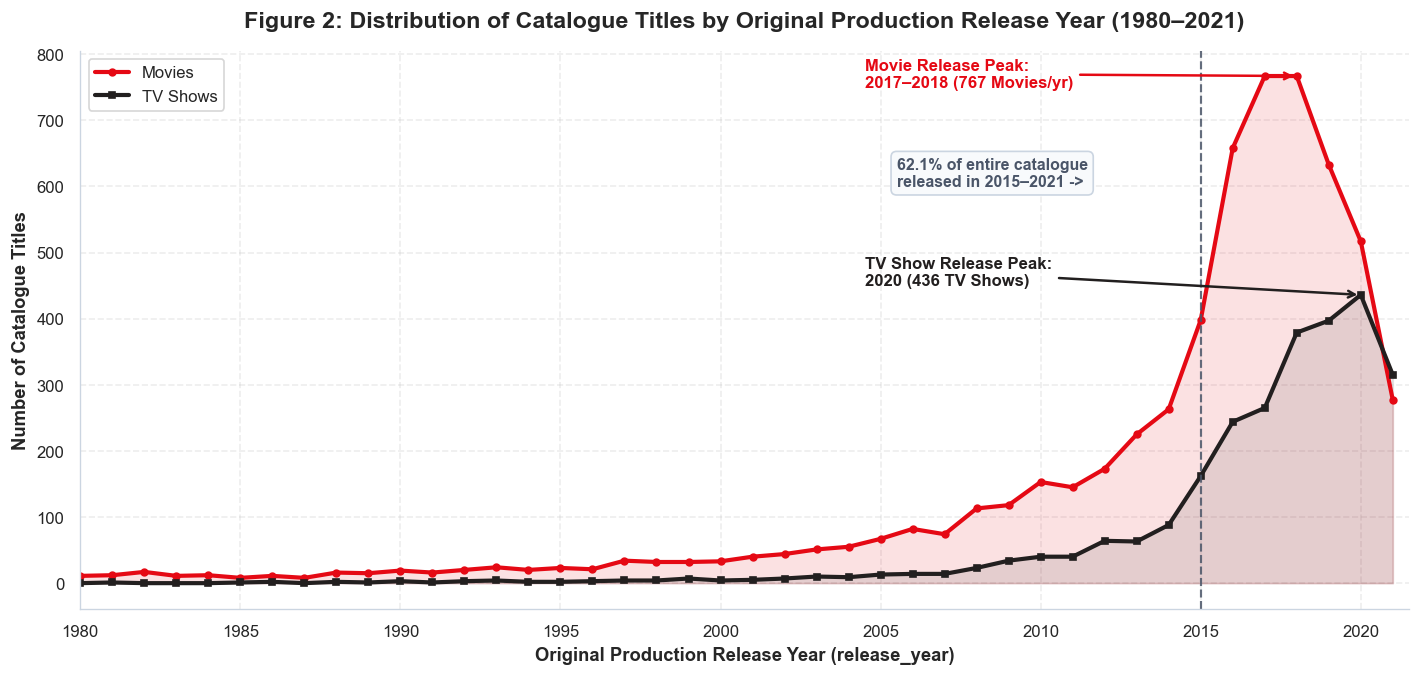

In [24]:
# VISUALIZATION 2: Release Year Distribution (Historical Production Curve, 1980-2021 + Full Inset)
fig, ax = plt.subplots(figsize=(12, 5.8))

rel_by_type = pd.crosstab(df_clean["release_year"], df_clean["type"])
rel_modern = rel_by_type[rel_by_type.index >= 1980]

ax.plot(rel_modern.index, rel_modern["Movie"], color=COLOR_RED, linewidth=2.5, marker="o", markersize=4, label="Movies")
ax.plot(rel_modern.index, rel_modern["TV Show"], color=COLOR_DARK, linewidth=2.5, marker="s", markersize=4, label="TV Shows")
ax.fill_between(rel_modern.index, rel_modern["Movie"], color=COLOR_RED, alpha=0.12)
ax.fill_between(rel_modern.index, rel_modern["TV Show"], color=COLOR_DARK, alpha=0.10)

# Annotate peak production years
ax.annotate("Movie Release Peak:\n2017–2018 (767 Movies/yr)", xy=(2018, 767), xytext=(2004.5, 750),
            arrowprops=dict(arrowstyle="->", color=COLOR_RED, lw=1.5), fontweight="bold", fontsize=10, color=COLOR_RED)
ax.annotate("TV Show Release Peak:\n2020 (436 TV Shows)", xy=(2020, 436), xytext=(2004.5, 450),
            arrowprops=dict(arrowstyle="->", color=COLOR_DARK, lw=1.5), fontweight="bold", fontsize=10, color=COLOR_DARK)

ax.axvline(2015, color=COLOR_SLATE, linestyle="--", linewidth=1.3, alpha=0.85)
ax.text(2005.5, 600, "62.1% of entire catalogue\nreleased in 2015–2021 ->", fontsize=9.5, fontweight="bold", color=COLOR_SLATE,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="#F8FAFC", edgecolor="#CBD5E1"))

ax.set_title("Figure 2: Distribution of Catalogue Titles by Original Production Release Year (1980–2021)", pad=14)
ax.set_xlabel("Original Production Release Year (release_year)")
ax.set_ylabel("Number of Catalogue Titles")
ax.set_xlim(1980, 2021.5)
ax.legend(loc="upper left", frameon=True)
sns.despine(top=True, right=True)

plt.tight_layout()
save_fig(fig, "02_release_year_distribution.png")
plt.show()

#### Analytical Interpretation — Figure 2: Release Year Distribution
* **What the chart shows:** The count of Movies and TV Shows present in the 2021 Netflix catalogue plotted by their original production `release_year` (focused on 1980–2021, which covers $98.4\%$ of all catalogue records).
* **What pattern is observable:** The distribution is heavily left-skewed toward recent releases: **$84.85\%$** of all titles were released from 2010 onward, and **$62.08\%$** were released between 2015 and 2021. Movie production vintage peaked in **2017–2018** ($767$ Movies per year), whereas TV Show production vintage continued climbing through **2020** ($436$ TV Shows, vs. $380$ in 2018).
* **Why the finding matters:** Netflix's library exhibits a strong **recency bias**, especially for TV Shows (median release year **2018**, IQR $2016–2020$) compared to Movies (median release year **2017**, IQR $2013–2019$). Older pre-2000 classics represent a niche archival tail rather than the core catalogue offering.
* **Relevant limitations:** The drop in `release_year == 2021` ($592$ titles) reflects both the September 2021 dataset cutoff and COVID-19 production delays from 2020–2021, not necessarily a permanent reduction in content output.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\03_top_10_countries.png


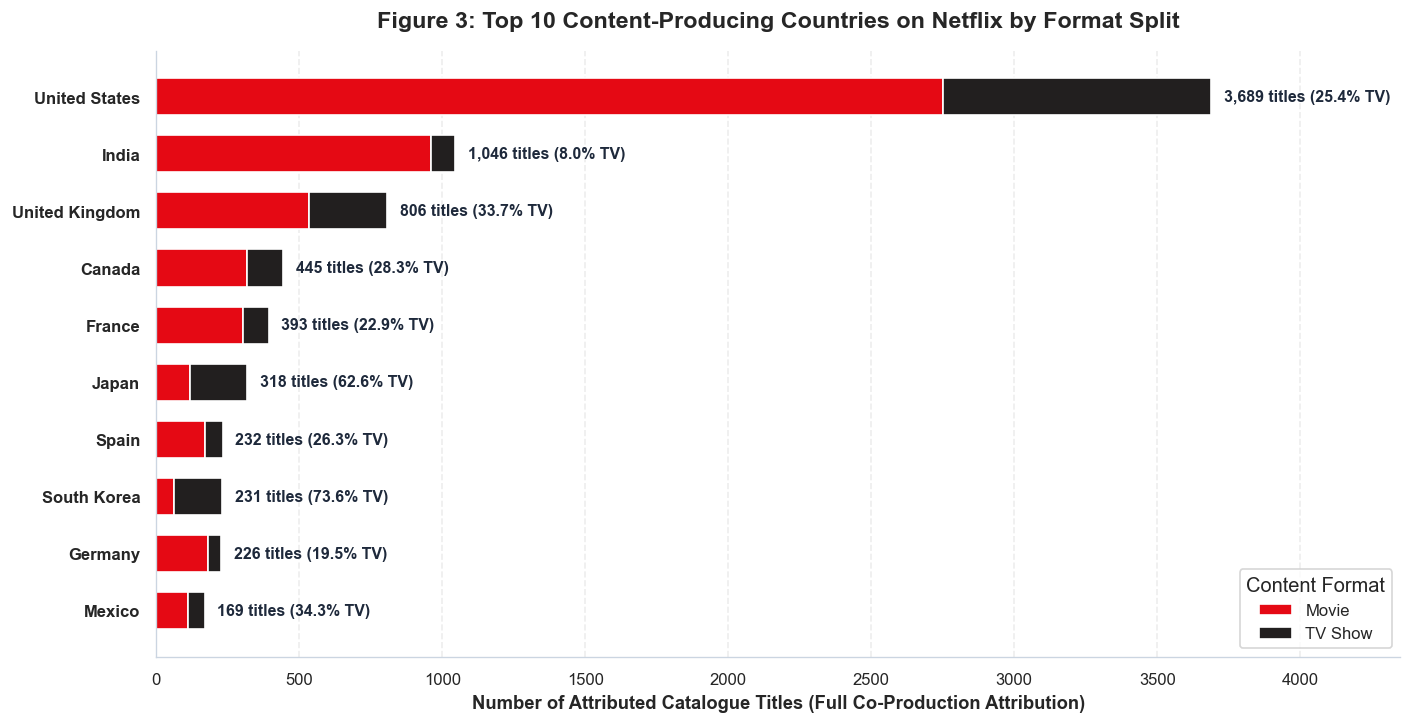

In [25]:
# VISUALIZATION 3: Top 10 Countries by Title Count (Stacked by Content Format)
fig, ax = plt.subplots(figsize=(12, 6.2))

ct_plot = country_type_ct.iloc[::-1]
y_pos = np.arange(len(ct_plot))

bars_m = ax.barh(y_pos, ct_plot["Movie"], color=COLOR_RED, height=0.65, label="Movie")
bars_t = ax.barh(y_pos, ct_plot["TV Show"], left=ct_plot["Movie"], color=COLOR_DARK, height=0.65, label="TV Show")

ax.set_yticks(y_pos)
ax.set_yticklabels(ct_plot.index, fontweight="bold")
ax.set_xlabel("Number of Attributed Catalogue Titles (Full Co-Production Attribution)")
ax.set_title("Figure 3: Top 10 Content-Producing Countries on Netflix by Format Split", pad=14)
ax.set_xlim(0, 4350)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", title="Content Format")
sns.despine(top=True, right=True)

for idx, (country, row) in enumerate(ct_plot.iterrows()):
    tot = int(row["Total_Credits"])
    tv_sh = row["TV_Show_Share (%)"]
    ax.text(tot + 45, idx, f"{tot:,} titles ({tv_sh:.1f}% TV)", va="center", ha="left", fontsize=9.5, fontweight="bold", color="#1E293B")

plt.tight_layout()
save_fig(fig, "03_top_10_countries.png")
plt.show()

#### Analytical Interpretation — Figure 3: Top 10 Countries by Title Count
* **What the chart shows:** The top 10 content-contributing countries across the Netflix catalogue (after exploding multi-country co-productions), segmented into Movies and TV Shows with each country's TV Show share annotated.
* **What pattern is observable:**
  1. **Geographic Concentration:** The **United States** leads by a wide margin with **$3,689$ title credits** ($46.27\%$ of all geo-tagged titles), followed by **India** ($1,046$, $13.12\%$) and the **United Kingdom** ($806$, $10.11\%$).
  2. **Structural Format Divergence across Regions:** Western markets (US, UK, Canada, France, Spain, Germany) maintain balanced portfolios with $20\%–34\%$ TV Shows. In stark contrast, **India is overwhelmingly film-centric** (**$92.0\%$ Movies**, only $8.0\%$ TV Shows), whereas East Asian hubs **South Korea** (**$73.6\%$ TV Shows**) and **Japan** (**$62.6\%$ TV Shows**) are overwhelmingly television-centric (driven by K-Dramas and Anime series).
* **Why the finding matters:** Netflix's regional acquisition strategy is highly tailored to local industrial strengths—licensing high-volume Bollywood/regional Indian cinema in South Asia while investing in serialized episodic content in South Korea and Japan.
* **Relevant limitations:** $831$ titles ($9.44\%$) lack country metadata, and multi-country co-productions ($16.55\%$ of geo-tagged titles) credit every participating country equally without distinguishing primary financing share.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\04_top_10_genres.png


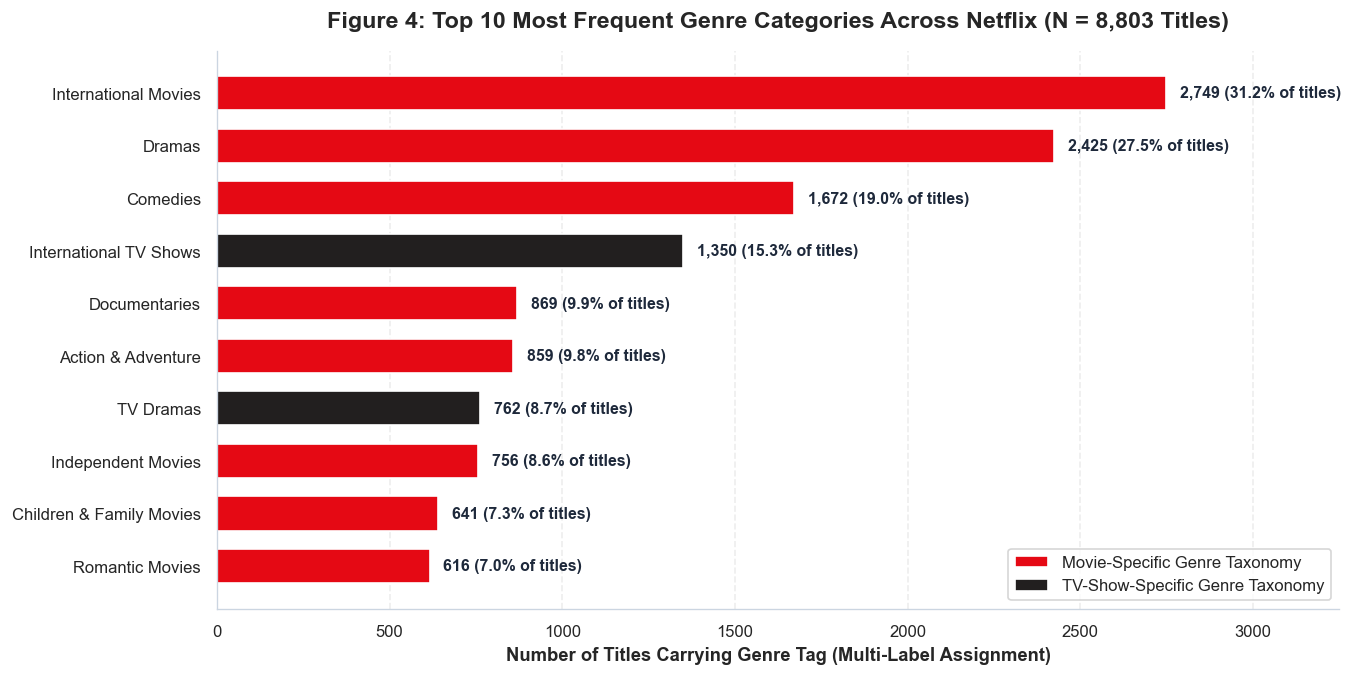

In [26]:
# VISUALIZATION 4: Top 10 Overall Genres Across the Netflix Catalogue
fig, ax = plt.subplots(figsize=(11.5, 5.8))

top10_g = df_genres["genre_name"].value_counts().head(10).iloc[::-1]
top10_g_pct = (top10_g / len(df_clean) * 100)

bar_colors = [COLOR_RED if "TV" not in g else COLOR_DARK for g in top10_g.index]
bars = ax.barh(top10_g.index, top10_g.values, color=bar_colors, height=0.65)

ax.set_title("Figure 4: Top 10 Most Frequent Genre Categories Across Netflix (N = 8,803 Titles)", pad=14)
ax.set_xlabel("Number of Titles Carrying Genre Tag (Multi-Label Assignment)")
ax.set_xlim(0, 3250)
ax.grid(axis="y", visible=False)
sns.despine(top=True, right=True)

for bar, pct in zip(bars, top10_g_pct.values):
    w = int(bar.get_width())
    ax.text(w + 40, bar.get_y() + bar.get_height()/2, f"{w:,} ({pct:.1f}% of titles)",
            va="center", ha="left", fontsize=9.5, fontweight="bold", color="#1E293B")

# Custom legend explaining color coding
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=COLOR_RED, label="Movie-Specific Genre Taxonomy"),
    Patch(facecolor=COLOR_DARK, label="TV-Show-Specific Genre Taxonomy")
]
ax.legend(handles=legend_handles, loc="lower right")

plt.tight_layout()
save_fig(fig, "04_top_10_genres.png")
plt.show()

#### Analytical Interpretation — Figure 4: Top 10 Overall Genres
* **What the chart shows:** The top 10 most frequently assigned genre tags across all $19,315$ exploded genre classifications, alongside the percentage of total catalogue titles ($N = 8,803$) carrying each tag.
* **What pattern is observable:** `International Movies` (**$2,749$ titles, $31.2\%$**), `Dramas` (**$2,425$ titles, $27.5\%$**), and `Comedies` (**$1,672$ titles, $19.0\%$**) occupy the top three positions, followed by `International TV Shows` (**$1,350$ titles, $15.3\%$**) and `Documentaries` (**$869$ titles, $9.9\%$**).
* **Why the finding matters:** Combined, `International Movies` and `International TV Shows` appear on **$4,099$ titles ($46.56\%$ of the entire catalogue)**, demonstrating that non-US/global content is a core pillar of Netflix's catalogue volume rather than a peripheral category.
* **Relevant limitations:** Because Netflix assigns up to 3 genre tags per title (mean $2.19$) and separates Movie genres (`Dramas`) from TV genres (`TV Dramas`), raw overall rankings favor Movie genres simply because Movies outnumber TV Shows $2.29 : 1$. Figure 10 resolves this by stratifying genres within each format.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\05_movie_duration_distribution.png


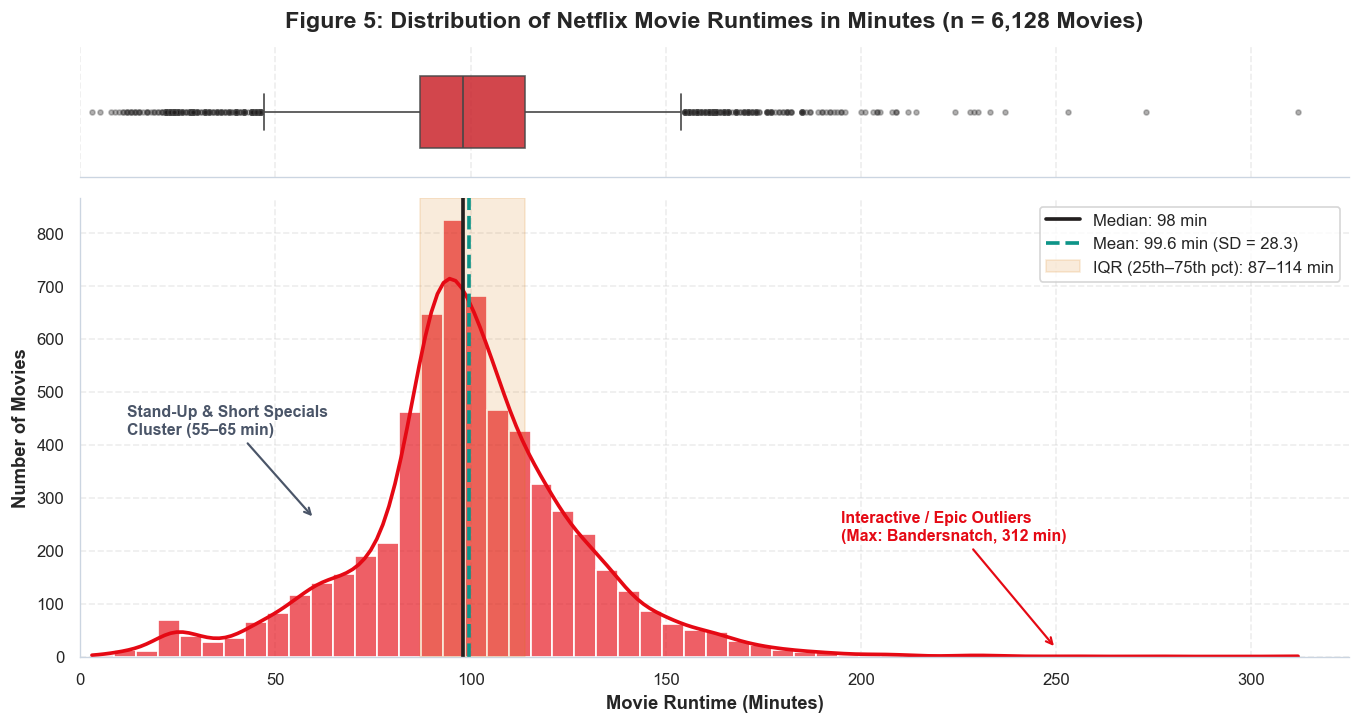

In [27]:
# VISUALIZATION 5: Movie Duration Distribution (Boxplot + Histogram + KDE + Statistical Markers)
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(11.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [0.22, 0.78]}
)

dur_data = movies_df["duration_min"].dropna()

# Top panel: Horizontal Boxplot highlighting IQR and Tukey outliers
sns.boxplot(
    x=dur_data, ax=ax_box, color=COLOR_RED, width=0.55,
    boxprops=dict(alpha=0.85), flierprops=dict(marker="o", markersize=3, alpha=0.35, markerfacecolor=COLOR_DARK)
)
ax_box.set_xlabel("")
ax_box.set_yticks([])
ax_box.set_title("Figure 5: Distribution of Netflix Movie Runtimes in Minutes (n = 6,128 Movies)", pad=12)
sns.despine(ax=ax_box, left=True, top=True, right=True)

# Bottom panel: Histogram + KDE + Reference Lines
sns.histplot(dur_data, bins=55, kde=True, ax=ax_hist, color=COLOR_RED, edgecolor="white", alpha=0.65, line_kws={"linewidth": 2.2, "color": COLOR_DARK})

mean_v = dur_data.mean()
med_v = dur_data.median()
q1_v, q3_v = dur_data.quantile([0.25, 0.75])

ax_hist.axvline(med_v, color=COLOR_DARK, linestyle="-", linewidth=2.2, label=f"Median: {med_v:.0f} min")
ax_hist.axvline(mean_v, color=COLOR_TEAL, linestyle="--", linewidth=2.2, label=f"Mean: {mean_v:.1f} min (SD = {dur_data.std():.1f})")
ax_hist.axvspan(q1_v, q3_v, color=COLOR_AMBER, alpha=0.14, label=f"IQR (25th–75th pct): {q1_v:.0f}–{q3_v:.0f} min")

ax_hist.annotate("Stand-Up & Short Specials\nCluster (55–65 min)", xy=(60, 260), xytext=(12, 420),
                 arrowprops=dict(arrowstyle="->", color=COLOR_SLATE, lw=1.3), fontsize=9.5, fontweight="bold", color=COLOR_SLATE)
ax_hist.annotate("Interactive / Epic Outliers\n(Max: Bandersnatch, 312 min)", xy=(250, 15), xytext=(195, 220),
                 arrowprops=dict(arrowstyle="->", color=COLOR_RED, lw=1.3), fontsize=9.5, fontweight="bold", color=COLOR_RED)

ax_hist.set_xlabel("Movie Runtime (Minutes)")
ax_hist.set_ylabel("Number of Movies")
ax_hist.set_xlim(0, 325)
ax_hist.legend(loc="upper right", frameon=True)
sns.despine(ax=ax_hist, top=True, right=True)

plt.tight_layout()
save_fig(fig, "05_movie_duration_distribution.png")
plt.show()

#### Analytical Interpretation — Figure 5: Movie Duration Distribution
* **What the chart shows:** A combined Tukey boxplot and histogram with kernel density estimate (KDE) of movie runtimes (`duration_min`) across all $6,128$ Movies in the catalogue.
* **What pattern is observable:** The distribution is unimodal and tightly concentrated around standard feature-length cinema: the **median runtime is $98.0$ minutes** and the **mean is $99.56$ minutes** ($\text{SD} = 28.30$ min), with the middle $50\%$ of movies ($\text{IQR}$) falling between **$87$ and $114$ minutes**. A secondary shoulder appears around **$55–65$ minutes** (driven by one-hour Stand-Up Comedy specials and documentaries), alongside a right tail extending beyond $150$ minutes (driven by Indian cinema and interactive specials like *Black Mirror: Bandersnatch* at $312$ min).
* **Why the finding matters:** Despite housing all non-episodic content under the single umbrella label `Movie`, the distribution confirms three distinct sub-populations: short films/specials ($<46.5$ min, $249$ titles), standard feature films ($80–130$ min), and extended international/interactive features ($>154.5$ min, $201$ titles).
* **Relevant limitations:** For interactive branching titles like *Black Mirror: Bandersnatch* ($312$ min) and *Headspace: Unwind Your Mind* ($273$ min), `duration_min` records the total footage across all interactive pathways rather than a single linear viewing experience.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\06_tv_show_season_distribution.png


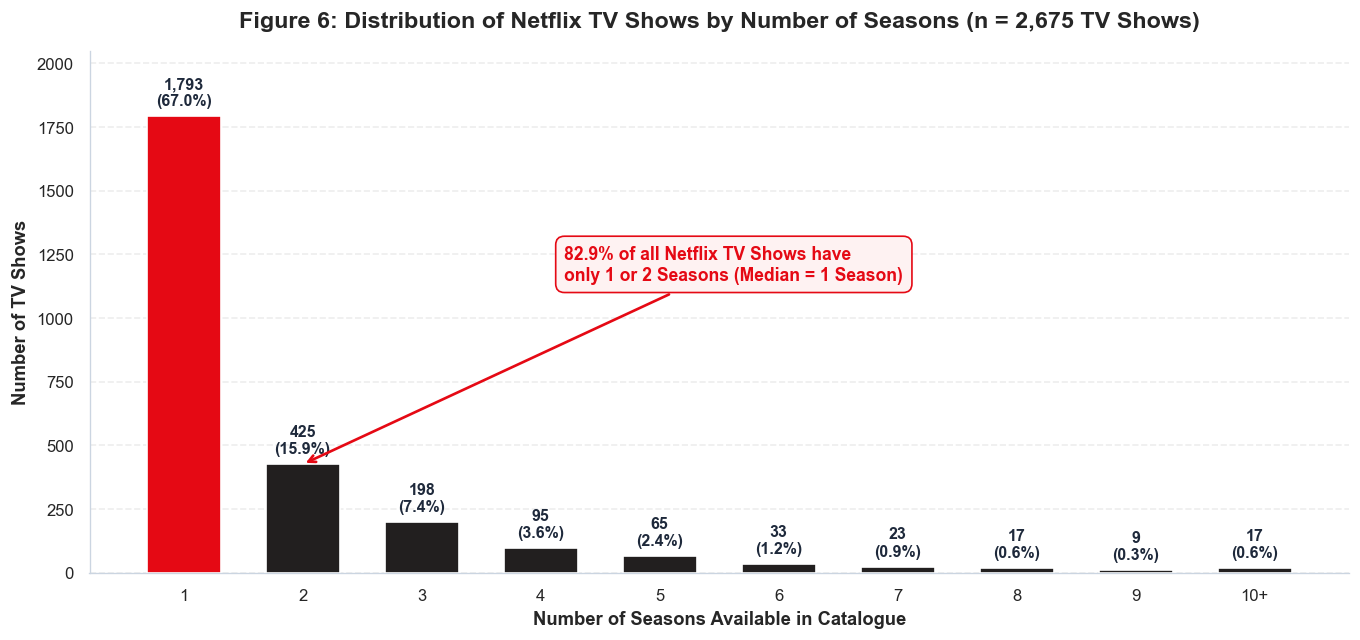

In [28]:
# VISUALIZATION 6: TV Show Season Count Distribution
fig, ax = plt.subplots(figsize=(11.5, 5.5))

# Group 10+ seasons into a tail bucket for clean visual presentation while showing exact numbers
tv_seasons_series = tv_df["seasons"].astype(int)
s_binned = tv_seasons_series.apply(lambda x: f"{x}" if x < 10 else "10+")
bin_order = [str(i) for i in range(1, 10)] + ["10+"]
s_counts = s_binned.value_counts().reindex(bin_order, fill_value=0)
s_pcts = s_counts / len(tv_df) * 100

bar_colors_tv = [COLOR_RED if idx == "1" else COLOR_DARK for idx in s_counts.index]
bars = ax.bar(s_counts.index, s_counts.values, color=bar_colors_tv, width=0.62)

ax.set_title("Figure 6: Distribution of Netflix TV Shows by Number of Seasons (n = 2,675 TV Shows)", pad=14)
ax.set_xlabel("Number of Seasons Available in Catalogue")
ax.set_ylabel("Number of TV Shows")
ax.set_ylim(0, 2050)
ax.grid(axis="x", visible=False)
sns.despine(top=True, right=True)

for bar, pct in zip(bars, s_pcts.values):
    h = int(bar.get_height())
    ax.text(bar.get_x() + bar.get_width()/2, h + 30, f"{h:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#1E293B")

ax.annotate("82.9% of all Netflix TV Shows have\nonly 1 or 2 Seasons (Median = 1 Season)",
            xy=(1, 425), xytext=(3.2, 1150),
            arrowprops=dict(arrowstyle="->", color=COLOR_RED, lw=1.6),
            fontsize=10.5, fontweight="bold", color=COLOR_RED,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="#FEF2F2", edgecolor=COLOR_RED, lw=1))

plt.tight_layout()
save_fig(fig, "06_tv_show_season_distribution.png")
plt.show()

#### Analytical Interpretation — Figure 6: TV Show Season Distribution
* **What the chart shows:** The discrete frequency distribution of season counts across all $2,675$ TV Shows on Netflix.
* **What pattern is observable:** The distribution exhibits extreme right-skewness (geometric/power-law decay): exactly **$1,793$ TV Shows ($67.03\%$)** have only **1 Season**, and **$425$ TV Shows ($15.89\%$)** have **2 Seasons**. Cumulatively, **$82.92\%$** of all television series on Netflix have $\le 2$ seasons, while only **$3.14\%$ ($84$ series)** reach 6 or more seasons (peaking at *Grey's Anatomy* with 17 seasons).
* **Why the finding matters:** This heavy concentration in 1–2 season series reflects three structural dynamics: (1) widespread global prevalence of limited miniseries, docuseries, and single-season K-dramas; (2) recent original series commissioned between 2019 and 2021 that had only aired their debut season by the snapshot date; and (3) streaming industry economics where series face high cancellation thresholds after Season 1 or 2.
* **Relevant limitations:** The `duration` field does not distinguish between a completed limited series (e.g., *The Queen's Gambit*, designed as 1 season), an ongoing newly launched series, or a cancelled 1-season show.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\07_content_rating_distribution.png


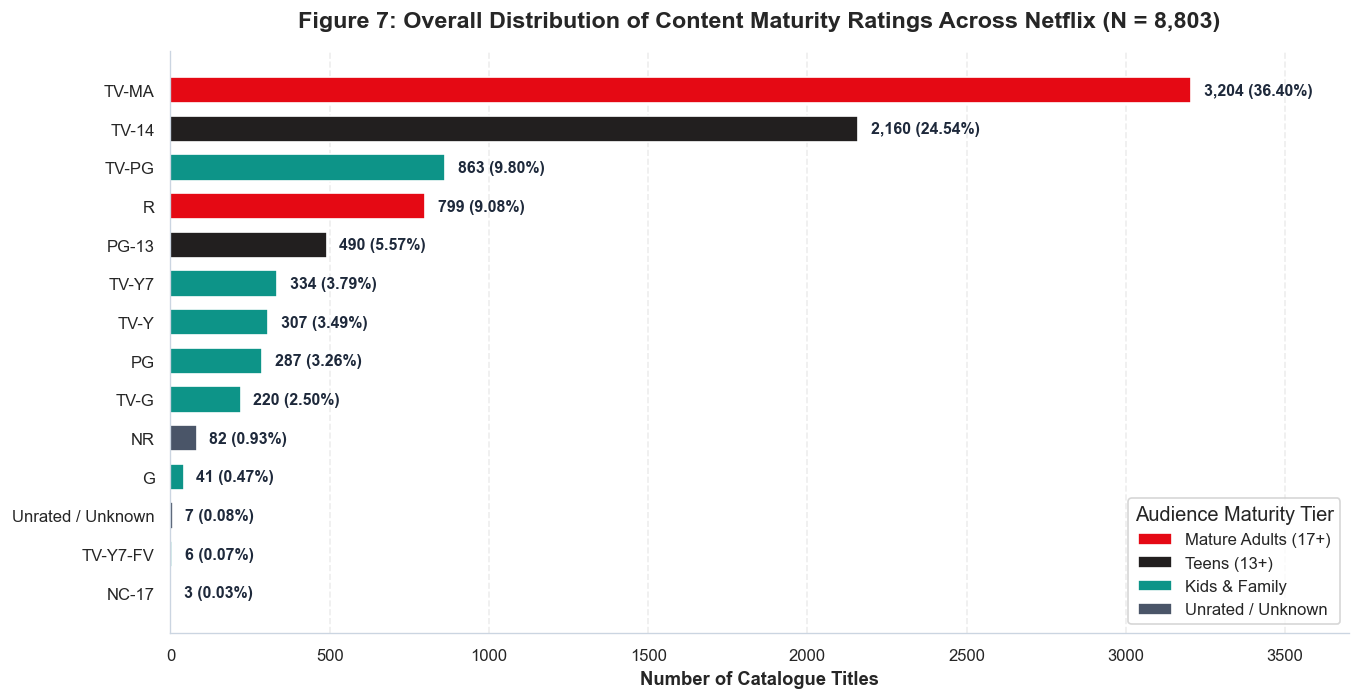

In [29]:
# VISUALIZATION 7: Overall Content Rating Distribution (Color-Coded by Audience Maturity Tier)
fig, ax = plt.subplots(figsize=(11.5, 6.0))

r_counts = df_clean["rating_clean"].value_counts().iloc[::-1]
r_pcts = (r_counts / len(df_clean) * 100)

TIER_COLORS = {
    "Mature Adults (17+)": COLOR_RED,
    "Teens (13+)": COLOR_DARK,
    "Kids & Family": COLOR_TEAL,
    "Unrated / Unknown": COLOR_SLATE
}
bar_colors_r = [TIER_COLORS[MATURITY_TIER_MAP[r]] for r in r_counts.index]

bars = ax.barh(r_counts.index, r_counts.values, color=bar_colors_r, height=0.68)
ax.set_title("Figure 7: Overall Distribution of Content Maturity Ratings Across Netflix (N = 8,803)", pad=14)
ax.set_xlabel("Number of Catalogue Titles")
ax.set_xlim(0, 3700)
ax.grid(axis="y", visible=False)
sns.despine(top=True, right=True)

for bar, pct in zip(bars, r_pcts.values):
    w = int(bar.get_width())
    ax.text(w + 40, bar.get_y() + bar.get_height()/2, f"{w:,} ({pct:.2f}%)",
            va="center", ha="left", fontsize=9.5, fontweight="bold", color="#1E293B")

legend_patches = [Patch(facecolor=col, label=tier) for tier, col in TIER_COLORS.items()]
ax.legend(handles=legend_patches, title="Audience Maturity Tier", loc="lower right")

plt.tight_layout()
save_fig(fig, "07_content_rating_distribution.png")
plt.show()

#### Analytical Interpretation — Figure 7: Content Rating Distribution
* **What the chart shows:** The frequency and percentage share of all 14 standardized rating categories across the catalogue ($N = 8,803$), color-coded by their harmonized Audience Maturity Tier.
* **What pattern is observable:** Adult and teen ratings overwhelmingly dominate the catalogue: **`TV-MA` ($3,204$ titles, $36.40\%$)** and **`TV-14` ($2,160$ titles, $24.54\%$)** together account for **$60.93\%$** of the entire library. Combined with theatrical equivalents `R` ($799$, $9.08\%$), `PG-13` ($490$, $5.57\%$), and `NC-17` ($3$, $0.03\%$), **Mature Adults ($45.51\%$) and Teens ($30.10\%$) represent $75.61\%$ of Netflix's catalogue**, whereas all Kids & Family categories combined (`TV-PG`, `TV-Y7`, `TV-Y`, `PG`, `TV-G`, `G`, `TV-Y7-FV`) represent **$23.38\%$**.
* **Why the finding matters:** Netflix positions its core catalogue primarily for adult and young-adult viewers rather than general family/children audiences, contrasting sharply with family-first competitors such as Disney+.
* **Relevant limitations:** Netflix applies US television ratings (`TV-MA`, `TV-14`, `TV-PG`) broadly to international and streaming-first Movies as well as TV Shows, meaning `TV-*` prefixes do not imply the title is a television series.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\08_yearly_content_addition_trends.png


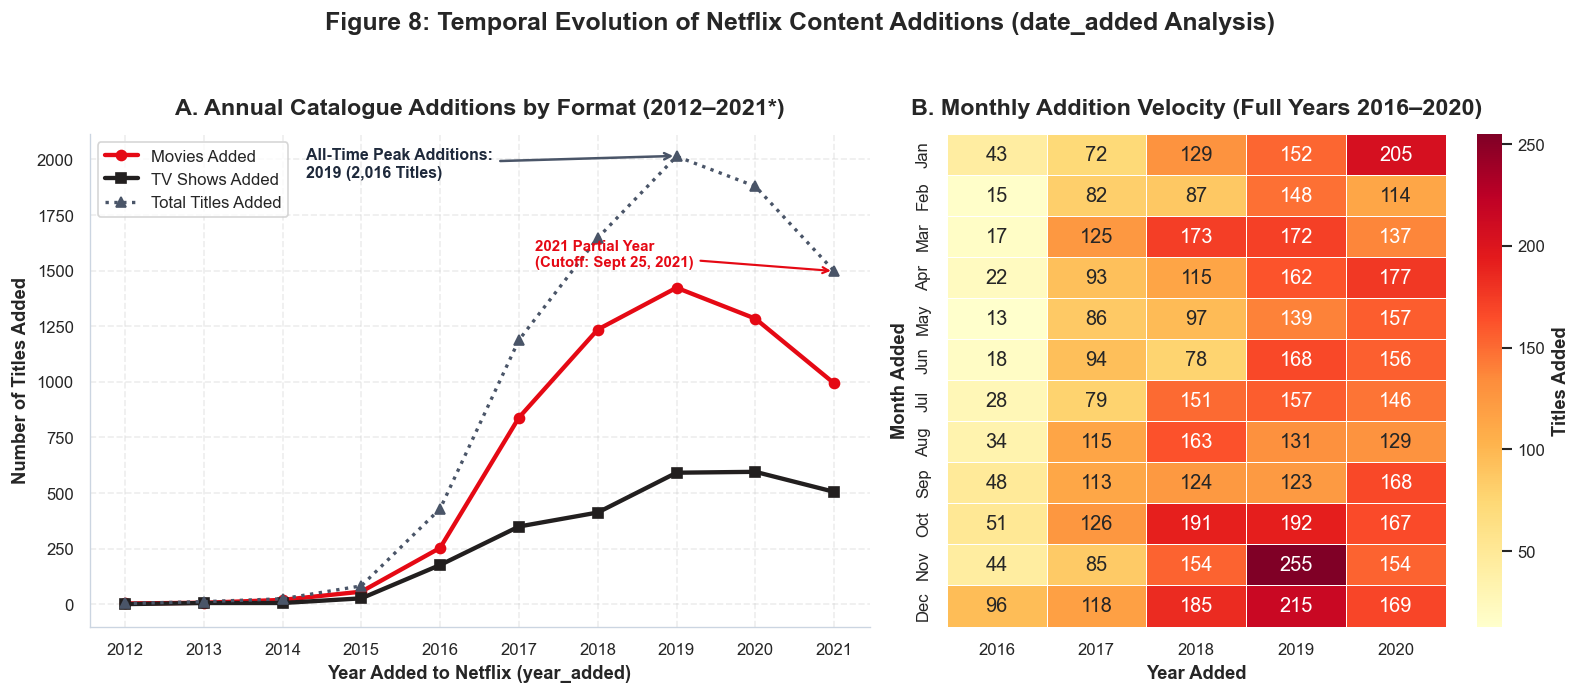

In [30]:
# VISUALIZATION 8: Yearly & Monthly Content Addition Trends (date_added, 2012-2021)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})

# Left panel: Yearly additions by content type (2012-2021)
add_yr = pd.crosstab(df_clean["year_added"], df_clean["type"])
add_yr_sub = add_yr[add_yr.index >= 2012]

ax1.plot(add_yr_sub.index, add_yr_sub["Movie"], color=COLOR_RED, marker="o", linewidth=2.6, markersize=6, label="Movies Added")
ax1.plot(add_yr_sub.index, add_yr_sub["TV Show"], color=COLOR_DARK, marker="s", linewidth=2.6, markersize=6, label="TV Shows Added")
ax1.plot(add_yr_sub.index, add_yr_sub.sum(axis=1), color=COLOR_SLATE, linestyle=":", marker="^", linewidth=2.0, label="Total Titles Added")

ax1.annotate("All-Time Peak Additions:\n2019 (2,016 Titles)", xy=(2019, 2016), xytext=(2014.3, 1920),
             arrowprops=dict(arrowstyle="->", color=COLOR_SLATE, lw=1.5), fontsize=9.5, fontweight="bold", color="#1E293B")
ax1.annotate("2021 Partial Year\n(Cutoff: Sept 25, 2021)", xy=(2021, 1498), xytext=(2017.2, 1520),
             arrowprops=dict(arrowstyle="->", color=COLOR_RED, lw=1.3), fontsize=9, fontweight="bold", color=COLOR_RED)

ax1.set_title("A. Annual Catalogue Additions by Format (2012–2021*)", pad=12)
ax1.set_xlabel("Year Added to Netflix (year_added)")
ax1.set_ylabel("Number of Titles Added")
ax1.set_xticks(range(2012, 2022))
ax1.legend(loc="upper left")
sns.despine(ax=ax1, top=True, right=True)

# Right panel: Month x Year Addition Heatmap (2016-2020 Full Calendar Years)
full_yrs = df_clean[df_clean["year_added"].isin([2016, 2017, 2018, 2019, 2020])]
hm_add = pd.crosstab(full_yrs["month_name_added"], full_yrs["year_added"]).reindex(MONTH_ORDER)
hm_add.index = [m[:3] for m in hm_add.index]

sns.heatmap(hm_add, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "Titles Added"}, ax=ax2, linewidths=0.5)
ax2.set_title("B. Monthly Addition Velocity (Full Years 2016–2020)", pad=12)
ax2.set_xlabel("Year Added")
ax2.set_ylabel("Month Added")

fig.suptitle("Figure 8: Temporal Evolution of Netflix Content Additions (date_added Analysis)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "08_yearly_content_addition_trends.png")
plt.show()

#### Analytical Interpretation — Figure 8: Yearly & Monthly Content Addition Trends
* **What the chart shows:** Panel A tracks annual content additions (`year_added`) broken down by Movies, TV Shows, and Total Titles from 2012 through September 2021; Panel B presents a Month $\times$ Year heatmap of additions across the five complete expansion years (2016–2020).
* **What pattern is observable:**
  1. **Exponential Expansion Phase (2015–2019):** Annual additions surged nearly **25-fold** from $82$ titles in 2015 to an all-time peak of **$2,016$ titles in 2019** ($1,424$ Movies and $592$ TV Shows), coinciding with Netflix's global expansion across 190 countries in 2016.
  2. **Post-2019 Resilience of TV Shows:** Between 2019 and 2020, total additions dipped by $6.8\%$ ($2,016 \rightarrow 1,879$), driven entirely by a decline in Movie additions ($1,424 \rightarrow 1,284$), while **TV Show additions actually reached a new record of $595$ titles in 2020**.
  3. **Seasonality:** Across full calendar years, additions peak around **July, October, November, and December** (summer vacation and Q4 holiday licensing refresh windows) and dip in **February**.
* **Why the finding matters:** Distinguishing `date_added` from `release_year` proves that Netflix's massive 2016–2019 expansion involved both new originals and large batch acquisitions of back-catalogue titles.
* **Relevant limitations:** First, 2021 covers only January 1 – September 25, 2021 ($1,498$ titles in ~8.8 months, which annualizes to ~$2,040$ titles/year). Second, because this is a static 2021 snapshot, titles that were added in 2013–2017 and subsequently **expired/removed** before September 2021 are absent (survivorship bias).

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\09_content_ratings_by_type.png


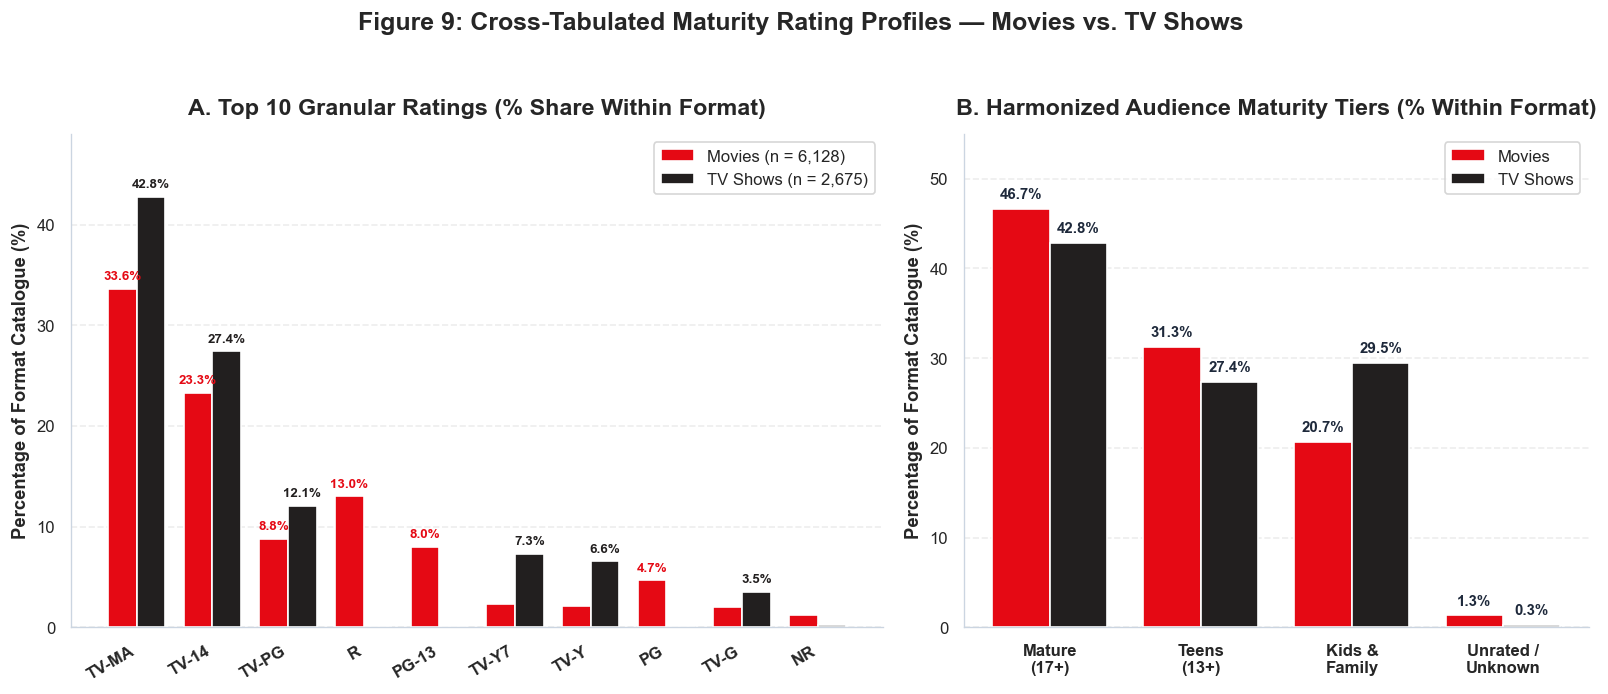

In [31]:
# VISUALIZATION 9: Content Ratings by Content Type (Proportional Share Comparison)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [1.3, 1]})

# Panel A: Granular ratings (% within Movie vs % within TV Show)
top_ratings_order = df_clean["rating_clean"].value_counts().head(10).index
r_by_type_pct = (pd.crosstab(df_clean["rating_clean"], df_clean["type"], normalize="columns") * 100).loc[top_ratings_order]

x = np.arange(len(top_ratings_order))
width = 0.38

rects1 = ax1.bar(x - width/2, r_by_type_pct["Movie"], width, label="Movies (n = 6,128)", color=COLOR_RED)
rects2 = ax1.bar(x + width/2, r_by_type_pct["TV Show"], width, label="TV Shows (n = 2,675)", color=COLOR_DARK)

ax1.set_title("A. Top 10 Granular Ratings (% Share Within Format)", pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(top_ratings_order, rotation=30, ha="right", fontweight="bold")
ax1.set_ylabel("Percentage of Format Catalogue (%)")
ax1.set_ylim(0, 49)
ax1.legend(loc="upper right")
ax1.grid(axis="x", visible=False)
sns.despine(ax=ax1, top=True, right=True)

for rect in rects1:
    h = rect.get_height()
    if h >= 3.0:
        ax1.text(rect.get_x() + rect.get_width()/2, h + 0.6, f"{h:.1f}%", ha="center", va="bottom", fontsize=8, color=COLOR_RED, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    if h >= 3.0:
        ax1.text(rect.get_x() + rect.get_width()/2, h + 0.6, f"{h:.1f}%", ha="center", va="bottom", fontsize=8, color=COLOR_DARK, fontweight="bold")

# Panel B: Harmonized Audience Maturity Tiers by Content Type
tier_order = ["Mature Adults (17+)", "Teens (13+)", "Kids & Family", "Unrated / Unknown"]
tier_pct = (pd.crosstab(df_clean["maturity_tier"], df_clean["type"], normalize="columns") * 100).loc[tier_order]

x2 = np.arange(len(tier_order))
b1 = ax2.bar(x2 - width/2, tier_pct["Movie"], width, label="Movies", color=COLOR_RED)
b2 = ax2.bar(x2 + width/2, tier_pct["TV Show"], width, label="TV Shows", color=COLOR_DARK)

ax2.set_title("B. Harmonized Audience Maturity Tiers (% Within Format)", pad=12)
ax2.set_xticks(x2)
ax2.set_xticklabels(["Mature\n(17+)", "Teens\n(13+)", "Kids &\nFamily", "Unrated /\nUnknown"], fontweight="bold")
ax2.set_ylabel("Percentage of Format Catalogue (%)")
ax2.set_ylim(0, 55)
ax2.legend(loc="upper right")
ax2.grid(axis="x", visible=False)
sns.despine(ax=ax2, top=True, right=True)

for rect in list(b1) + list(b2):
    h = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1E293B")

fig.suptitle("Figure 9: Cross-Tabulated Maturity Rating Profiles — Movies vs. TV Shows", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "09_content_ratings_by_type.png")
plt.show()

#### Analytical Interpretation — Figure 9: Content Ratings by Content Type
* **What the chart shows:** Panel A compares the relative within-format percentage share of the top 10 granular rating categories between Movies and TV Shows; Panel B compares the two formats across our harmonized 4-tier Audience Maturity taxonomy (which reconciles MPAA theatrical ratings `R`, `PG-13`, `PG`, `G` with TV Parental Guidelines `TV-MA`, `TV-14`, `TV-PG`, `TV-Y7`, `TV-Y`).
* **What pattern is observable:**
  1. **Regulatory Taxonomy Artifact (Panel A):** MPAA ratings (`R`, `PG-13`, `PG`, `G`) appear almost exclusively on Movies ($13.0\%$ `R`, $8.0\%$ `PG-13`, $4.7\%$ `PG`), while TV Shows rely exclusively on TV Parental Guidelines ($42.8\%$ `TV-MA`, $27.4\%$ `TV-14`, $12.1\%$ `TV-PG`).
  2. **True Audience Maturity Difference (Panel B):** Once MPAA and TV ratings are harmonized into unified maturity tiers, Movies skew slightly more toward **Mature Adults ($46.7\%$ vs. $42.8\%$)** and **Teens ($31.3\%$ vs. $27.4\%$)**, whereas **TV Shows dedicate a substantially higher share to Kids & Family programming ($29.5\%$ of TV Shows vs. $20.7\%$ of Movies)**.
* **Why the finding matters:** Looking only at raw rating strings (`TV-MA` at $42.8\%$ for TV Shows vs. $33.6\%$ for Movies) misleads naive analysts into concluding that TV Shows are more mature than Movies—ignoring that an additional $13.0\%$ of Movies carry the theatrical `R` rating! Harmonizing the rating scales flips that naive conclusion and reveals that TV Shows are actually much more heavily weighted toward Kids & Family series ($29.5\%$) than Movies ($20.7\%$).
* **Relevant limitations:** Regional rating boards differ slightly in exact age thresholds, and $89$ records ($1.01\%$) are unrated (`NR` or missing).

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\10_genre_comparisons_by_type.png


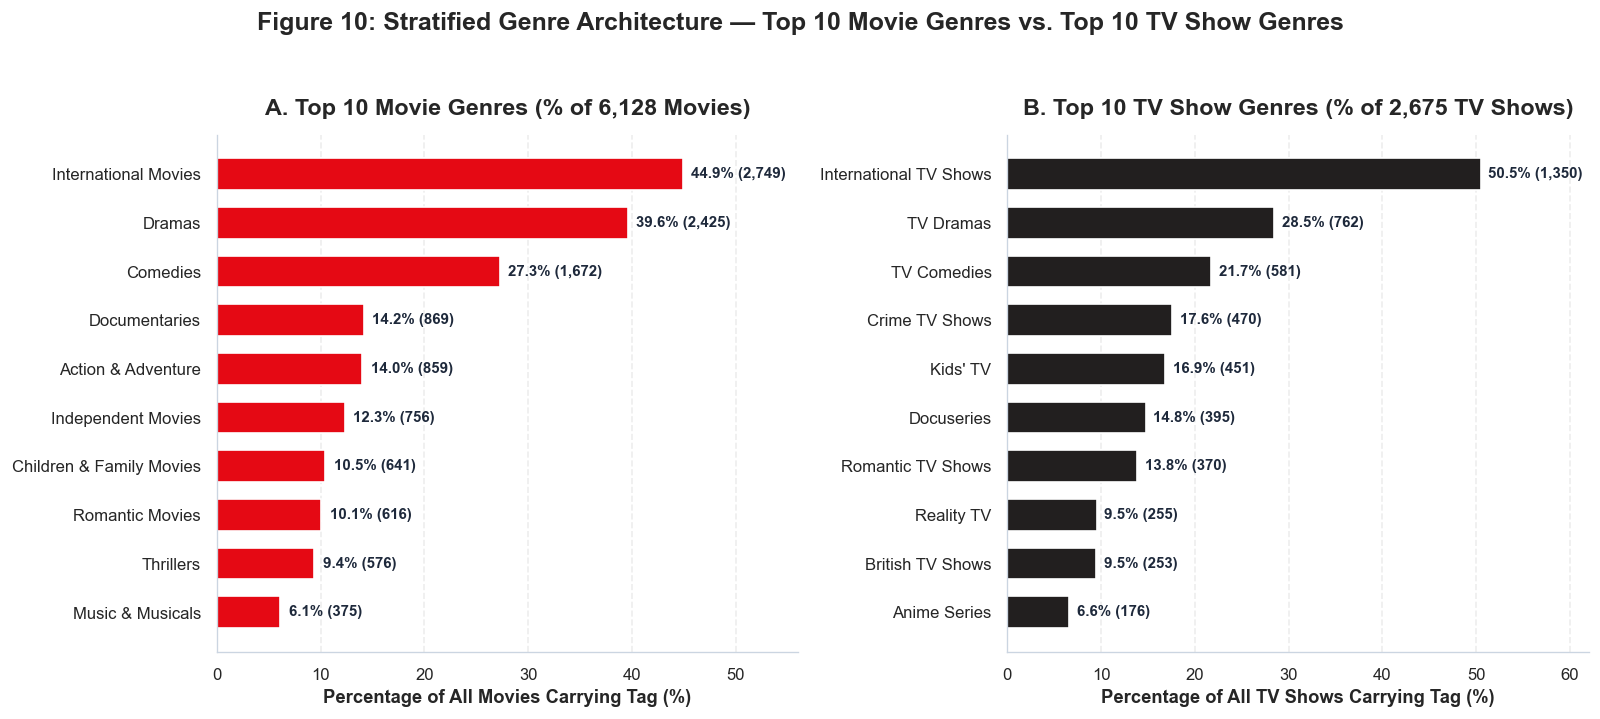

In [32]:
# VISUALIZATION 10: Stratified Genre Comparison by Content Format (Top 10 Movie vs Top 10 TV Genres)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.8))

m_g10 = df_genres[df_genres["type"] == "Movie"]["genre_name"].value_counts().head(10).iloc[::-1]
m_g10_pct = m_g10 / (df_clean["type"] == "Movie").sum() * 100

t_g10 = df_genres[df_genres["type"] == "TV Show"]["genre_name"].value_counts().head(10).iloc[::-1]
t_g10_pct = t_g10 / (df_clean["type"] == "TV Show").sum() * 100

bars1 = ax1.barh(m_g10.index, m_g10_pct.values, color=COLOR_RED, height=0.65)
ax1.set_title("A. Top 10 Movie Genres (% of 6,128 Movies)", pad=12)
ax1.set_xlabel("Percentage of All Movies Carrying Tag (%)")
ax1.set_xlim(0, 56)
ax1.grid(axis="y", visible=False)
sns.despine(ax=ax1, top=True, right=True)

for bar, cnt in zip(bars1, m_g10.values):
    w = bar.get_width()
    ax1.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}% ({cnt:,})",
             va="center", ha="left", fontsize=9, fontweight="bold", color="#1E293B")

bars2 = ax2.barh(t_g10.index, t_g10_pct.values, color=COLOR_DARK, height=0.65)
ax2.set_title("B. Top 10 TV Show Genres (% of 2,675 TV Shows)", pad=12)
ax2.set_xlabel("Percentage of All TV Shows Carrying Tag (%)")
ax2.set_xlim(0, 62)
ax2.grid(axis="y", visible=False)
sns.despine(ax=ax2, top=True, right=True)

for bar, cnt in zip(bars2, t_g10.values):
    w = bar.get_width()
    ax2.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}% ({cnt:,})",
             va="center", ha="left", fontsize=9, fontweight="bold", color="#1E293B")

fig.suptitle("Figure 10: Stratified Genre Architecture — Top 10 Movie Genres vs. Top 10 TV Show Genres", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "10_genre_comparisons_by_type.png")
plt.show()

#### Analytical Interpretation — Figure 10: Genre Comparisons by Content Type
* **What the chart shows:** A side-by-side stratified comparison of the top 10 Movie genres (expressed as a percentage of all $6,128$ Movies) and the top 10 TV Show genres (expressed as a percentage of all $2,675$ TV Shows).
* **What pattern is observable:**
  1. **Parallel Core Pillars:** Both formats are anchored by International content (`International Movies` on **$44.9\%$** of Movies; `International TV Shows` on **$50.5\%$** of TV Shows), Drama (`Dramas` on **$39.6\%$** of Movies; `TV Dramas` on **$28.5\%$** of TV Shows), and Comedy (`Comedies` on **$27.3\%$** of Movies; `TV Comedies` on **$21.7\%$** of TV Shows).
  2. **Format-Specific Genre Niches:** TV Shows exhibit distinct episodic genre pillars that have no equally prominent movie counterpart: **`Crime TV Shows` ($17.6\%$ of TV Shows)**, **`Kids' TV` ($16.9\%$)**, **`Docuseries` ($14.8\%$)**, **`Reality TV` ($9.5\%$)**, **`British TV Shows` ($9.5\%$)**, and **`Anime Series` ($6.6\%$)**. Conversely, Movies feature high shares of **`Action & Adventure` ($14.0\%$)** and **`Independent Movies` ($12.3\%$)**.
* **Why the finding matters:** Stratifying by `type` eliminates the sample-size distortion of the 70/30 Movie-to-TV split and reveals that international sourcing is actually even higher among TV Shows ($50.5\%$) than among Movies ($44.9\%$).
* **Relevant limitations:** Genre tags are non-mutually exclusive (a single K-Drama can simultaneously be tagged `International TV Shows`, `TV Dramas`, and `Romantic TV Shows`), so percentages sum to $>100\%$ within each panel.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\11_country_genre_heatmap.png


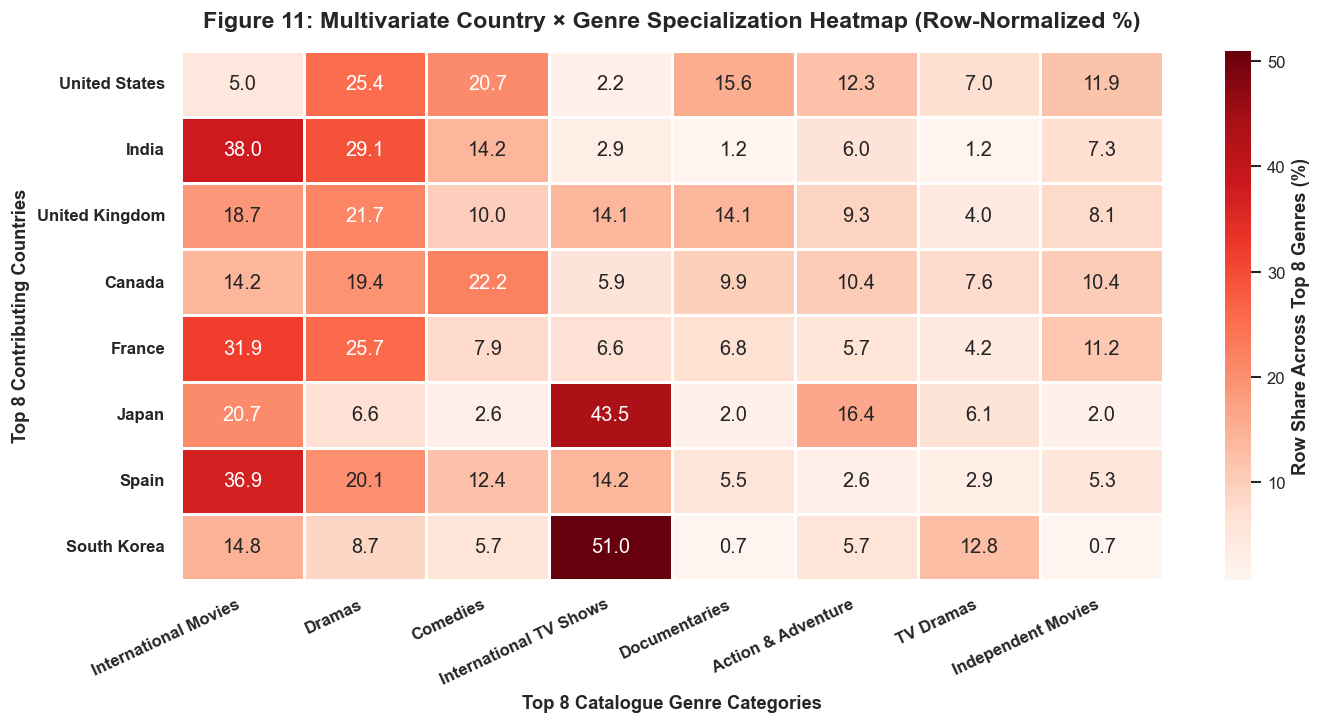

In [33]:
# VISUALIZATION 11: Multivariate Country x Genre Row-Normalized Specialization Heatmap
fig, ax = plt.subplots(figsize=(12, 6.2))

sns.heatmap(
    cg_matrix_pct,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    linewidths=0.8,
    cbar_kws={"label": "Row Share Across Top 8 Genres (%)"},
    ax=ax
)

ax.set_title("Figure 11: Multivariate Country × Genre Specialization Heatmap (Row-Normalized %)", pad=14)
ax.set_xlabel("Top 8 Catalogue Genre Categories")
ax.set_ylabel("Top 8 Contributing Countries")
plt.xticks(rotation=25, ha="right", fontweight="bold")
plt.yticks(rotation=0, fontweight="bold")

plt.tight_layout()
save_fig(fig, "11_country_genre_heatmap.png")
plt.show()

#### Analytical Interpretation — Figure 11: Multivariate Country × Genre Specialization Heatmap
* **What the chart shows:** A row-normalized specialization matrix across the top 8 producing countries and top 8 catalogue genres, showing how each country's genre tags are distributed across major categories.
* **What pattern is observable:**
  * **Domestic vs. International Tagging Structure:** For the **United States**, `Dramas` ($25.4\%$), `Comedies` ($20.7\%$), `Documentaries` ($15.6\%$), `Action & Adventure` ($12.3\%$), and `Independent Movies` ($11.9\%$) lead across top-8 genre assignments, with very low `International Movies` ($5.0\%$, arising only from US–foreign co-productions).
  * **India's Dramatic & Cinematic Concentration:** India's tags concentrate heavily in `International Movies` ($38.0\%$), `Dramas` ($29.1\%$), and `Comedies` ($14.2\%$), with minimal representation in TV genres ($2.9\%$ `International TV Shows`).
  * **East Asian Episodic Concentration:** **South Korea** ($51.0\%$ `International TV Shows`, $12.8\%$ `TV Dramas`) and **Japan** ($43.5\%$ `International TV Shows`, $16.4\%$ `Action & Adventure`) specialize sharply in serialized television and action/anime storytelling.
  * **Anglophone Documentary Strength:** The **United States** ($15.6\%$) and **United Kingdom** ($14.1\%$) dedicate a far larger share of their top-8 genre output to `Documentaries` than India ($1.2\%$) or South Korea ($0.7\%$).
* **Why the finding matters:** This multivariate view answers **RQ07** by demonstrating that geographic origin strongly conditions genre supply on Netflix.
* **Relevant limitations:** `International Movies` and `International TV Shows` act as meta-geographic genre tags applied by Netflix US to non-domestic content, which mechanically elevates their row percentage for all non-US countries.

[Saved Figure] -> c:\Users\HP\Desktop\kaggle project 1\netflix-content-analytics\visuals\12_acquisition_lag_distribution.png


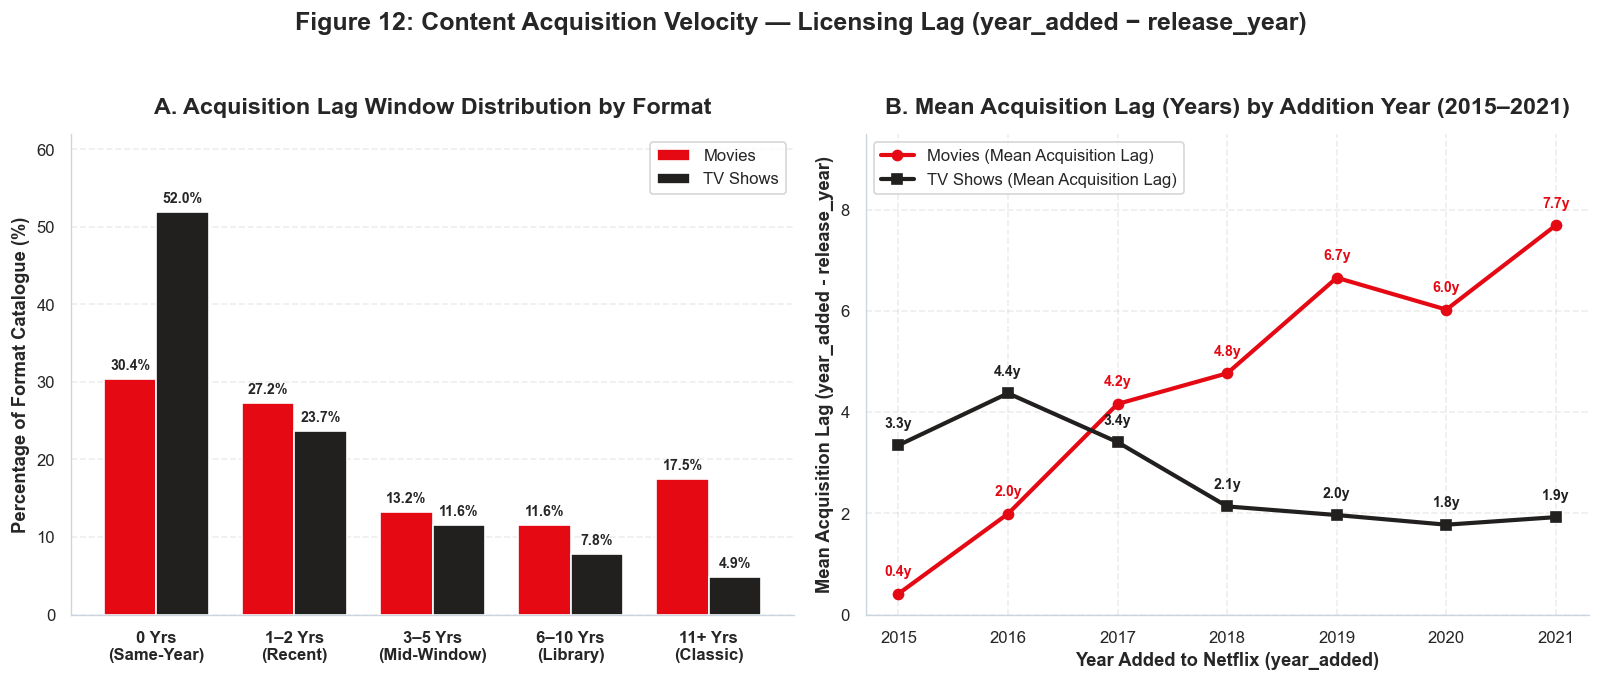

In [34]:
# VISUALIZATION 12: Acquisition Lag Analysis (year_added - release_year) by Content Type
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.5))

# Panel A: Categorical Lag Bucket Comparison (Movies vs TV Shows)
def categorize_lag(lag):
    if pd.isna(lag) or lag < 0:
        return np.nan
    elif lag == 0:
        return "0 Yrs (Same-Year / Original)"
    elif lag <= 2:
        return "1–2 Yrs (Recent License)"
    elif lag <= 5:
        return "3–5 Yrs (Mid-Window)"
    elif lag <= 10:
        return "6–10 Yrs (Older Library)"
    else:
        return "11+ Yrs (Classic / Archival)"

BUCKET_ORDER = [
    "0 Yrs (Same-Year / Original)",
    "1–2 Yrs (Recent License)",
    "3–5 Yrs (Mid-Window)",
    "6–10 Yrs (Older Library)",
    "11+ Yrs (Classic / Archival)"
]

valid_lag_df["lag_bucket"] = valid_lag_df["acquisition_lag"].apply(categorize_lag)
lag_ct_pct = (pd.crosstab(valid_lag_df["lag_bucket"], valid_lag_df["type"], normalize="columns") * 100).loc[BUCKET_ORDER]

x_b = np.arange(len(BUCKET_ORDER))
w_b = 0.38
r1 = ax1.bar(x_b - w_b/2, lag_ct_pct["Movie"], w_b, color=COLOR_RED, label="Movies")
r2 = ax1.bar(x_b + w_b/2, lag_ct_pct["TV Show"], w_b, color=COLOR_DARK, label="TV Shows")

ax1.set_title("A. Acquisition Lag Window Distribution by Format", pad=12)
ax1.set_xticks(x_b)
ax1.set_xticklabels(["0 Yrs\n(Same-Year)", "1–2 Yrs\n(Recent)", "3–5 Yrs\n(Mid-Window)", "6–10 Yrs\n(Library)", "11+ Yrs\n(Classic)"], fontweight="bold")
ax1.set_ylabel("Percentage of Format Catalogue (%)")
ax1.set_ylim(0, 62)
ax1.legend(loc="upper right")
ax1.grid(axis="x", visible=False)
sns.despine(ax=ax1, top=True, right=True)

for rect in list(r1) + list(r2):
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

# Panel B: Median & Mean Acquisition Lag Evolution over Addition Years (2015-2021)
lag_trend = (
    valid_lag_df[valid_lag_df["year_added"] >= 2015]
    .groupby(["year_added", "type"])["acquisition_lag"]
    .mean()
    .unstack()
)

ax2.plot(lag_trend.index, lag_trend["Movie"], color=COLOR_RED, marker="o", linewidth=2.5, label="Movies (Mean Acquisition Lag)")
ax2.plot(lag_trend.index, lag_trend["TV Show"], color=COLOR_DARK, marker="s", linewidth=2.5, label="TV Shows (Mean Acquisition Lag)")
ax2.set_title("B. Mean Acquisition Lag (Years) by Addition Year (2015–2021)", pad=12)
ax2.set_xlabel("Year Added to Netflix (year_added)")
ax2.set_ylabel("Mean Acquisition Lag (year_added - release_year)")
ax2.set_ylim(0, 9.5)
ax2.legend(loc="upper left")
sns.despine(ax=ax2, top=True, right=True)

for yr in lag_trend.index:
    m_val = lag_trend.loc[yr, "Movie"]
    t_val = lag_trend.loc[yr, "TV Show"]
    ax2.text(yr, m_val + 0.35, f"{m_val:.1f}y", ha="center", fontsize=8.5, fontweight="bold", color=COLOR_RED)
    ax2.text(yr, t_val + 0.35, f"{t_val:.1f}y", ha="center", fontsize=8.5, fontweight="bold", color=COLOR_DARK)

fig.suptitle("Figure 12: Content Acquisition Velocity — Licensing Lag (year_added − release_year)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "12_acquisition_lag_distribution.png")
plt.show()

#### Analytical Interpretation — Figure 12: Acquisition Lag Distribution (`year_added - release_year`)
* **What the chart shows:** Panel A compares the distribution of `acquisition_lag` (`year_added - release_year`) between Movies and TV Shows across five licensing age buckets; Panel B tracks how mean acquisition lag evolved from 2015 to 2021.
* **What pattern is observable:**
  1. **TV Shows Are Far More Immediate Than Movies:** Over half of all TV Shows (**$52.0\%$**) are added to Netflix in the **exact same calendar year** they are released ($\text{median lag} = 0.0$ years, $\text{mean} = 2.31$ years), compared to only **$30.4\%$** of Movies ($\text{median lag} = 2.0$ years, $\text{mean} = 5.73$ years).
  2. **Deep Movie Back-Catalogue Licensing:** Nearly a third of Movies (**$29.1\%$**) arrive on Netflix **6 or more years** after theatrical release ($11.6\%$ in the $6–10$ year window and $17.5\%$ in the $11+$ year classic window), compared to only **$12.7\%$** of TV Shows ($7.8\%$ in $6–10$ years and $4.9\%$ in $11+$ years). This gap widened markedly between 2018 and 2021 (Panel B, with Movie mean acquisition lag rising to $7.7$ years in 2021 vs. $1.9$ years for TV Shows) as Netflix licensed large packages of classic films while simultaneously premiering day-and-date original TV series.
* **Why the finding matters:** This directly reinforces the distinction between `release_year` and `date_added`: Movies rely heavily on post-theatrical and archival licensing windows, whereas TV Shows are heavily driven by first-run originals and immediate current-season ingestions.
* **Relevant limitations:** For multi-season returning TV shows, Netflix often updates `release_year` to the latest season's release year while retaining the original `date_added` of Season 1 (causing the 14 negative-lag records audited in Section 4, which were excluded from non-negative lag buckets).

---
## SECTION 9: Key Findings

Below is a synthesized summary of **10 evidence-based analytical findings** derived directly from the executed dataset ($N = 8,807$ raw records; $N = 8,803$ deduplicated unique titles):

1. **Catalogue Format Asymmetry (RQ01 — Section 6A & Figure 1):** Feature films dominate catalogue title volume, with **$6,128$ Movies ($69.61\%$)** vs. **$2,675$ TV Shows ($30.39\%$)**—a **$2.29 : 1$ ratio**. However, while Movies dominate unit title counts, TV Show additions grew faster proportionally during 2018–2021, rising from $25.0\%$ of annual additions in 2018 to $33.7\%$ in 2021.
2. **Forensic Data Quality Recovery — Zero True Duration Nulls & Structural Director Missingness (Section 4 & Section 5):** Auditing cross-column alignment revealed that all **3 missing `duration` records** (`s5542`, `s5795`, `s5814` — three Louis C.K. comedy specials) had their runtimes (`"74 min"`, `"84 min"`, `"66 min"`) accidentally shifted into the `rating` column. Restoring them yields **100.0% completeness in `duration`**. Additionally, `director` missingness ($29.91\%$ overall) is structurally concentrated in TV Shows (**$91.41\%$ missing** vs. only **$3.07\%$ in Movies**), confirming an MAR (Missing at Random conditioned on format) mechanism where dropping nulls would introduce severe selection bias.
3. **Geographic Concentration & Regional Format Specialization (RQ02 — Section 6C, 7.1 & Figure 3):** Across $7,972$ geo-tagged titles ($122$ unique countries), the **United States ($3,689$ credits, $46.27\%$ of known-country titles)**, **India ($1,046$, $13.12\%$)**, and the **United Kingdom ($806$, $10.11\%$)** lead production. More importantly, regional format specialization diverges sharply: **India is overwhelmingly film-centric ($92.0\%$ Movies vs. $8.0\%$ TV Shows)**, whereas **South Korea ($73.6\%$ TV Shows)** and **Japan ($62.6\%$ TV Shows)** specialize heavily in episodic television.
4. **Global & International Genre Footprint (RQ03 — Section 6D & Figure 4, Figure 10):** Across $19,315$ genre assignments ($42$ unique genres; mean $2.19$ genres/title), the top categories are `International Movies` (**$2,749$ titles, $31.23\%$ of catalogue**), `Dramas` (**$2,425$, $27.55\%$**), `Comedies` (**$1,672$, $18.99\%$**), and `International TV Shows` (**$1,350$, $15.34\%$**). Within their respective formats, international tags appear on **$44.86\%$ of all Movies** and **$50.47\%$ of all TV Shows**.
5. **Exponential Expansion Wave & Post-2019 Plateau (RQ04 — Section 6H & Figure 8):** Annual catalogue additions accelerated nearly 25-fold from **$82$ titles in 2015** to **$429$ in 2016**, **$1,188$ in 2017**, **$1,649$ in 2018**, and an all-time peak of **$2,016$ titles in 2019**, before moderating to **$1,879$ in 2020** (and $1,498$ through September 25, 2021). While Movie additions declined by $9.8\%$ between 2019 and 2020 ($1,424 \rightarrow 1,284$), TV Show additions reached a record high of **$595$ titles in 2020**.
6. **Production Recency Bias (Section 6B & Figure 2):** Although original release years span nearly a century (**1925–2021**), **$84.85\%$** of all catalogue titles were released in **2010 or later**, and **$62.08\%$** were released in **2015 or later** (median Movie release year $= 2017$; median TV Show release year $= 2018$).
7. **Acquisition Lag Asymmetry Between Movies and TV Shows (RQ04 — Section 7.2 & Figure 12):** Comparing `year_added` against `release_year` proves that **$51.98\%$ of TV Shows** are added to Netflix in the **exact same calendar year** they premiere ($\text{median lag} = 0.0$ years, $\text{mean} = 2.31$ years), compared to only **$30.40\%$ of Movies** ($\text{median lag} = 2.0$ years, $\text{mean} = 5.73$ years). Conversely, **$29.12\%$ of Movies** are licensed back-catalogue titles added $6+$ years after theatrical release ($11.62\%$ in $6–10$ years; $17.50\%$ in $11+$ years), compared to only **$12.67\%$ of TV Shows**.
8. **Movie Runtime Distribution & Genre Stratification (RQ05 — Section 6F, 7.4 & Figure 5):** Movie runtimes ($n = 6,128$) average **$99.56$ minutes** ($\text{SD} = 28.30$) with a **median of $98.0$ minutes** and an **IQR of $27.0$ minutes ($87–114$ min)**. Tukey's $1.5\times\text{IQR}$ fences flag **$249$ short outliers ($<46.5$ min)** and **$201$ long outliers ($>154.5$ min)**. Stratifying by genre explains this variance: `Classic Movies` ($\text{median} = 112.0$ min) and `International Movies` ($\text{median} = 107.0$ min) run nearly twice as long as `Stand-Up Comedy` specials ($\text{median} = 62.0$ min) and `Children & Family Movies` ($\text{median} = 88.0$ min).
9. **Single-Season Dominance in TV Shows (RQ05 — Section 6G & Figure 6):** Among all $2,675$ TV Shows, **$1,793$ ($67.03\%$)** consist of only **1 Season**, and **$2,218$ ($82.92\%$)** have **$\le 2$ Seasons** ($\text{mean} = 1.76$ seasons, $\text{median} = 1.0$ season). Only **$3.14\%$ ($84$ series)** span 6 or more seasons.
10. **Adult Maturity Positioning & Format Rating Divergence (RQ06 & RQ07 — Section 6E, 7.3 & Figure 7, Figure 9, Figure 11):** Overall, `TV-MA` (**$3,204$ titles, $36.40\%$**) and `TV-14` (**$2,160$, $24.54\%$**) comprise **$60.93\%$** of the library. When MPAA film ratings (`R`, `PG-13`, `PG`, `G`) and TV Parental Guidelines (`TV-MA`, `TV-14`, `TV-PG`, `TV-Y7`, `TV-Y`) are harmonized into unified Audience Maturity Tiers, **$75.61\%$** of Netflix targets Mature Adults ($45.51\%$) or Teens ($30.10\%$). However, **TV Shows allocate a significantly larger share to Kids & Family programming ($29.50\%$)** than Movies (**$20.71\%$**).

---
## SECTION 10: Limitations & Epistemological Boundaries

A rigorous analytical report must state what the data **cannot** establish as clearly as what it shows:

1. **Lack of Demand-Side Viewership & Engagement Telemetry (Supply $\neq$ Demand):** The dataset contains zero metrics on subscriber viewing hours, completion rates, thumbs-up ratings, churn impact, or revenue contribution. High representation of `International Movies` or `TV-MA` titles reflects **catalogue supply and licensing volume**, not necessarily audience preference or ROI.
2. **Static Cross-Sectional Snapshot & Survivorship Bias:** The dataset captures titles active on Netflix up to **September 25, 2021**. It does not record licensing expiration dates (`date_removed`). Consequently, titles added in 2012–2017 whose licenses expired prior to late 2021 are absent from the snapshot, creating survivorship bias in historical addition analyses.
3. **Partial Observation Window in 2021:** Because data collection terminated on September 25, 2021, the 2021 calendar year misses Q4 (historically one of Netflix's highest addition quarters). Naive year-over-year comparisons that treat 2021 as a full year overstate the post-2020 slowdown.
4. **Equal-Weight Co-Production Attribution & Missing Geographies:** Exactly **$831$ titles ($9.44\%$)** lack country metadata, and for the **$1,319$ multi-country co-productions ($16.55\%$ of geo-tagged titles)**, comma-separated lists do not specify percentage of budget or primary creative origin.
5. **Ambiguity Between Netflix Originals and Exclusive/Non-Exclusive Licensed Titles:** The schema lacks an explicit boolean `is_netflix_original` column. While `acquisition_lag == 0` serves as a useful proxy for contemporary premieres, it includes both in-house Netflix Originals and same-year exclusive regional licensing deals.
6. **Unit-of-Analysis Inequivalence (`1 Movie` vs. `1 TV Show`):** Comparing Movies and TV Shows by title count treats a 60-minute stand-up special and a 15-season, 300-episode drama (*Supernatural*, *Grey's Anatomy*) as equal single units (`1 row`). Without episode counts and per-episode runtimes for TV Shows, total available streaming hours cannot be computed directly from `duration`.

---
## SECTION 11: Conclusion & Strategic Recommendations

### 11.1 Synthesis & Answers to Research Questions
This investigation examined $8,803$ unique titles in Netflix's global content catalogue across six structured analytical stages:
* **RQ01 (Composition):** Movies represent **$69.61\%$ ($6,128$)** of titles and TV Shows represent **$30.39\%$ ($2,675$)**, though TV Shows steadily gained share of annual additions through 2020–2021.
* **RQ02 (Geography):** Production is anchored by the **United States ($3,689$)**, **India ($1,046$)**, and the **UK ($806$)**, with stark format specialization between film-dominant India ($92.0\%$ Movies) and series-dominant South Korea ($73.6\%$ TV Shows) and Japan ($62.6\%$ TV Shows).
* **RQ03 (Genres):** `International Movies` ($31.2\%$), `Dramas` ($27.5\%$), `Comedies` ($19.0\%$), and `International TV Shows` ($15.3\%$) lead overall, while `Crime TV Shows`, `Kids' TV`, and `Docuseries` anchor episodic television.
* **RQ04 (Temporal Dynamics):** Additions surged from $82$ titles/year (2015) to $2,016$ titles/year (2019). Over half ($52.0\%$) of TV Shows arrive on Netflix in their release year ($\text{median lag} = 0$ yrs), whereas Movies blend contemporary releases with deep library licensing ($\text{median lag} = 2$ yrs; $29.1\%$ added $6+$ years post-release).
* **RQ05 (Durations):** Movies center tightly at a **median of $98$ minutes** ($\text{IQR } 87–114$ min), while TV Shows follow a steep power-law decay where **$67.0\%$ have 1 season** and **$82.9\%$ have $\le 2$ seasons**.
* **RQ06 (Ratings by Format):** While $75.6\%$ of the catalogue targets Mature Adults ($45.5\%$) or Teens ($30.1\%$), harmonizing MPAA and TV ratings reveals that TV Shows allocate a much higher share to **Kids & Family ($29.5\%$ vs. $20.7\%$ for Movies)**.
* **RQ07 (Multivariate Specialization):** Cross-tabulating country $\times$ genre reveals distinct regional comparative advantages: US/UK dominance in Documentaries, Indian specialization in feature Dramas/Comedies, and South Korean/Japanese specialization in serialized TV Dramas and Action/Anime.

### 11.2 Actionable Analytical & Data Engineering Recommendations
1. **Enrich Catalogue Metadata with Episode-Level Runtime & Originality Flags:** To measure true library volume in **streaming hours** rather than title counts, data engineering pipelines should join `netflix_titles` with IMDb/TMDB episode counts and total series runtimes, and add an explicit `sourcing_type` (`Original`, `Exclusive License`, `Non-Exclusive Library`) flag.
2. **Integrate Demand-Side Telemetry for Portfolio Efficiency Scoring:** Pair our Country $\times$ Genre $\times$ Maturity supply matrices with actual viewership hours (e.g., Netflix's bi-annual *What We Watched* engagement reports) to compute **Supply-to-Engagement Efficiency Ratios**—identifying underserved high-demand niches versus oversupplied low-engagement categories.
3. **Implement Automated Ingestion Validation Rules:** To prevent the schema contamination and near-duplicate anomalies discovered in Section 4, upstream ETL pipelines should enforce regex validation on `rating` (rejecting strings matching `\d+ min`), strip non-breaking whitespace (`\xa0`) on `title` and `date_added`, and enforce uniqueness constraints on `(lower(trim(title)), type, release_year)`.